# MobileNetV3-Large - Diabetic Retinopathy Grading
**EEEM068 Applied Machine Learning - University of Surrey**
Architecture experiment using **MobileNetV3-Large pre-trained on ImageNet-1k** (supervised, via `timm`).  
Baseline plus the same five experiments the team ran for MobileNetV3-Large, applied to MobileNetV3-Large under matching training conditions.
| Setting | Value |
|---|---|
| Architecture | MobileNetV3-Large (`mobilenetv3_large_100.ra_in1k`) |
| Pre-training | ImageNet-1k supervised |
| Loss (baseline) | CrossEntropyLoss (no class weights) |
| Sampler (baseline) | Standard shuffle |
| Augmentation (baseline) | Resize → RandomCrop → HFlip → Normalise |
| Normalisation | mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225) |
| Optimiser | AdamW, lr=1e-3, weight_decay=1e-2 |
| Scheduler | CosineAnnealingLR |
| Image size | 380x380 |
| Batch size | 64 |
| Epochs | 15 (early stopping on val_loss, patience=3) |
| Metric | Quadratic Weighted Kappa (QWK) |


## 1. Imports

In [1]:
import os
import json
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix
)
from sklearn.metrics import f1_score, accuracy_score

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

PyTorch : 2.5.1+cu121
timm    : 1.0.11
CUDA    : True


## 2. Configuration

In [2]:
# ── Paths ─────────────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'        # 13-stage preprocessed images
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

OUT_DIR     = ROOT / 'outputs' / 'mobilenet_dr_training'
CKPT_DIR    = OUT_DIR / 'checkpoints'
FIGURES_DIR = OUT_DIR / 'figures'
for d in (OUT_DIR, CKPT_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Experiment ────────────────────────────────────────────────
EXPERIMENT_NAME = 'mobilenet_dr_training'
MODEL_NAME      = 'vit_base_patch16_224.augreg_in21k_ft_in1k'

# ── Reproducibility ───────────────────────────────────────────
SEED = 42

# ── Data ──────────────────────────────────────────────────────
IMAGE_SIZE  = 224
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

# MobileNetV3-Large (IN21k) uses symmetric normalisation, not ImageNet RGB stats
VIT_MEAN = (0.5, 0.5, 0.5)
VIT_STD  = (0.5, 0.5, 0.5)

# ── Training ──────────────────────────────────────────────────
BATCH_SIZE               = 32
NUM_WORKERS              = 4
EPOCHS                   = 10
LR                       = 3e-4
WEIGHT_DECAY             = 1e-2
EARLY_STOPPING_PATIENCE  = 3

print('Config set. Root:', ROOT)
print(f'Images: {TRAIN_DIR.name} / {VAL_DIR.name} / {TEST_LABELS_DIR.name}')

Config set. Root: /workspace/AML_G14_CW
Images: train_proc / val_proc / test_labels_proc


In [3]:
# ── Seed + device ─────────────────────────────────────────────
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [4]:
# ── Checkpoint paths - defined once here, reused by every eval cell ──────────
# Running this cell is sufficient to resume evaluation after a kernel restart.
CKPT_BASELINE = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
CKPT_EXP1     = ROOT / 'outputs' / 'mobilenet_dr_training_exp1' / 'checkpoints' / 'mobilenet_dr_training_exp1_best.pt'
CKPT_EXP2     = ROOT / 'outputs' / 'mobilenet_dr_training_exp2' / 'checkpoints' / 'mobilenet_dr_training_exp2_best.pt'
CKPT_EXP3_P1  = ROOT / 'outputs' / 'mobilenet_dr_training_exp3' / 'checkpoints' / 'mobilenet_dr_training_exp3_phase1_best.pt'
CKPT_EXP3     = ROOT / 'outputs' / 'mobilenet_dr_training_exp3' / 'checkpoints' / 'mobilenet_dr_training_exp3_best.pt'
CKPT_EXP5     = ROOT / 'outputs' / 'mobilenet_dr_training_exp5' / 'checkpoints' / 'mobilenet_dr_training_exp5_best.pt'
CKPT_EXP6     = ROOT / 'outputs' / 'mobilenet_dr_training_exp6' / 'checkpoints' / 'mobilenet_dr_training_exp6_best.pt'
CKPT_EXP7     = ROOT / 'outputs' / 'mobilenet_dr_training_exp7' / 'checkpoints' / 'mobilenet_dr_training_exp7_best.pt'
CKPT_EXP8     = ROOT / 'outputs' / 'mobilenet_dr_training_exp8' / 'checkpoints' / 'mobilenet_dr_training_exp8_best.pt'
CKPT_EXP9     = ROOT / 'outputs' / 'mobilenet_dr_training_exp9' / 'checkpoints' / 'mobilenet_dr_training_exp9_best.pt'

print('Checkpoint registry:')
for label, path in [
    ('Baseline',  CKPT_BASELINE),
    ('Exp1',      CKPT_EXP1),
    ('Exp2',      CKPT_EXP2),
    ('Exp3 P1',   CKPT_EXP3_P1),
    ('Exp3',      CKPT_EXP3),
    ('Exp5',      CKPT_EXP5),
    ('Exp6',      CKPT_EXP6),
    ('Exp7',      CKPT_EXP7),
    ('Exp8',      CKPT_EXP8),
    ('Exp9',      CKPT_EXP9),
]:
    status = 'saved' if path.exists() else 'not yet trained'
    print(f'  {label:<12}: {path.relative_to(ROOT)}  [{status}]')


Checkpoint registry:
  Baseline    : outputs/mobilenet_dr_training/checkpoints/mobilenet_dr_training_best.pt  [not yet trained]
  Exp1        : outputs/mobilenet_dr_training_exp1/checkpoints/mobilenet_dr_training_exp1_best.pt  [not yet trained]
  Exp2        : outputs/mobilenet_dr_training_exp2/checkpoints/mobilenet_dr_training_exp2_best.pt  [not yet trained]
  Exp3 P1     : outputs/mobilenet_dr_training_exp3/checkpoints/mobilenet_dr_training_exp3_phase1_best.pt  [not yet trained]
  Exp3        : outputs/mobilenet_dr_training_exp3/checkpoints/mobilenet_dr_training_exp3_best.pt  [not yet trained]
  Exp5        : outputs/mobilenet_dr_training_exp5/checkpoints/mobilenet_dr_training_exp5_best.pt  [not yet trained]
  Exp6        : outputs/mobilenet_dr_training_exp6/checkpoints/mobilenet_dr_training_exp6_best.pt  [saved]
  Exp7        : outputs/mobilenet_dr_training_exp7/checkpoints/mobilenet_dr_training_exp7_best.pt  [saved]
  Exp8        : outputs/mobilenet_dr_training_exp8/checkpoints/mob

## 3. Load Pre-Split Data

In [5]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images  (dir: train/)')
print(f'Val   : {len(val_df):,} images   (dir: val/)')
print(f'Test  : {len(test_df):,} images   (dir: test_labels/)')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')

Train : 24,588 images  (dir: train/)
Val   : 5,269 images   (dir: val/)
Test  : 5,269 images   (dir: test_labels/)

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106


## 4. Dataset and DataLoaders

In [6]:
class DRDataset(Dataset):
    """Fundus image dataset. Reads images from data_dir using the 'image' column."""

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# MobileNet requires symmetric normalisation (0.5, 0.5, 0.5) - different from EfficientNet
train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

val_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

train_ds = DRDataset(train_df, TRAIN_DIR,       transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,         transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'Train loader: {len(train_loader)} batches/epoch')
print(f'Val loader  : {len(val_loader)} batches/epoch')
print(f'Test loader : {len(test_loader)} batches/epoch')

Train loader: 768 batches/epoch
Val loader  : 165 batches/epoch
Test loader : 165 batches/epoch


## 5. Model
`mobilenetv3_large_100.ra_in1k` - pre-trained on ImageNet-1k (1,000 classes) using the RandAugment recipe.  
The 1000-class classifier head is replaced with a 5-class linear layer for the DR grading task.


In [7]:
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,   # replaces the 1000-class head directly
)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model           : {MODEL_NAME}')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable:,}')
print(f'Classifier head : {model.head}')

Model           : vit_base_patch16_224.augreg_in21k_ft_in1k
Total params    : 85,802,501
Trainable params: 85,802,501
Classifier head : Linear(in_features=768, out_features=5, bias=True)


## 6. Loss, Optimiser, Scheduler

Identical to the baseline - no class weights, standard AdamW + cosine schedule.

In [8]:
criterion = nn.CrossEntropyLoss()   # no class weights - matching baseline conditions
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print('Loss      :', criterion)
print('Optimiser :', optimizer.__class__.__name__, f'lr={LR}')
print('Scheduler :', scheduler.__class__.__name__)

Loss      : CrossEntropyLoss()
Optimiser : AdamW lr=0.0003
Scheduler : CosineAnnealingLR


## 7. Training Loop

In [9]:
use_amp = device.type == 'cuda'
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)


def run_epoch(loader, train_mode: bool):
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, leave=False, desc='train' if train_mode else 'val'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return total_loss / total, all_labels, all_preds


print('run_epoch defined.')

run_epoch defined.


In [10]:
best_path     = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
best_val_loss = float('inf')
patience_left = EARLY_STOPPING_PATIENCE

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,   train_mode=False)
    scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, best_path)
        marker = '  ← best'
    else:
        patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {best_val_loss:.4f}  →  {best_path}')

## 8. Loss Curve

In [11]:
epochs_ran = range(1, len(history['train_loss']) + 1)

# ── Print table ────────────────────────────────────────────────
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(history['train_loss'], history['train_acc'],
        history['val_loss'],   history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

# ── Plot loss curve ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran, history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran, history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('MobileNetV3-Large (IN21k) - Train vs Validation Loss', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/mobilenet_dr_training/figures/{EXPERIMENT_NAME}_loss_curve.png')

## 9. Evaluation on Test Set

In [12]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_BASELINE, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {CKPT_BASELINE}')
print(f'epoch={ckpt["epoch"]}  val_loss={ckpt["val_loss"]:.4f}')

_, y_true, y_pred = run_epoch(test_loader, train_mode=False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
print(f'Quadratic Weighted Kappa: {cohen_kappa_score(y_true, y_pred, weights="quadratic"):.4f}')

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


In [13]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large (Test Set)', fontweight='bold')

thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/mobilenet_dr_training/figures/{EXPERIMENT_NAME}_confusion_matrix.png')

In [14]:
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large (Test Set, normalised)', fontweight='bold')

thresh = 0.5
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/mobilenet_dr_training/figures/{EXPERIMENT_NAME}_confusion_matrix_normalised.png')

## 10. Results Summary

[2026-05-09 05:50:29] TEST  loss=0.6384  acc=0.7965  qwk=0.6394  f1=0.4422

classification report:
               precision    recall  f1-score   support

        No DR     0.8386    0.9623    0.8962      3872
         Mild     0.2083    0.0137    0.0256       366
     Moderate     0.5696    0.5101    0.5382       794
       Severe     0.5789    0.1679    0.2604       131
Proliferative     0.7358    0.3679    0.4906       106

     accuracy                         0.7965      5269
    macro avg     0.5863    0.4044    0.4422      5269
 weighted avg     0.7458    0.7965    0.7578      5269

test_qwk=0.6394  test_acc=0.7965  test_f1_macro=0.4422  best_epoch=4


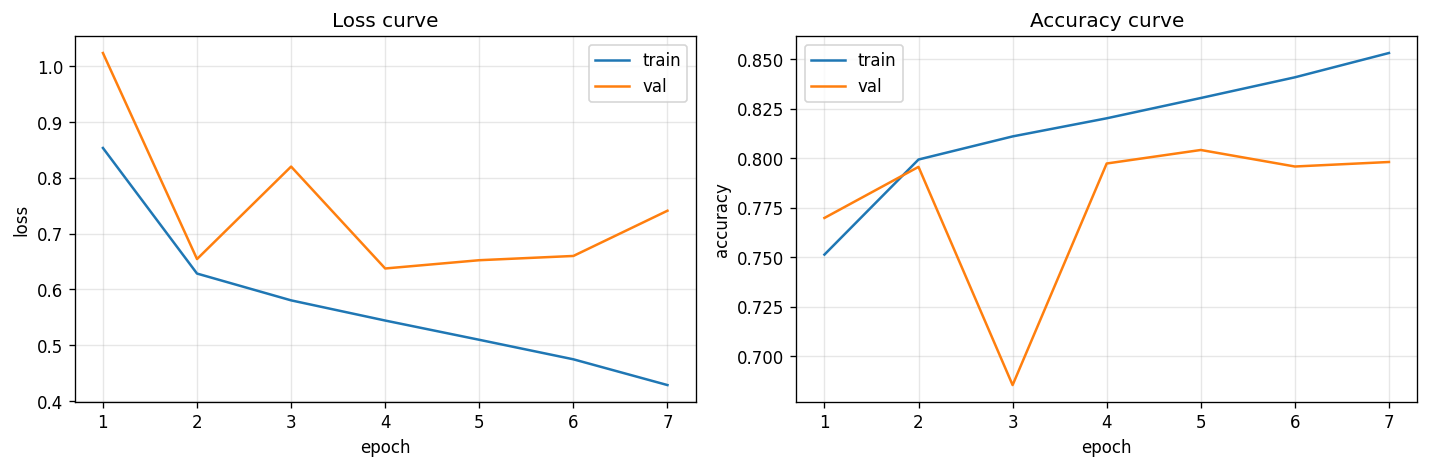

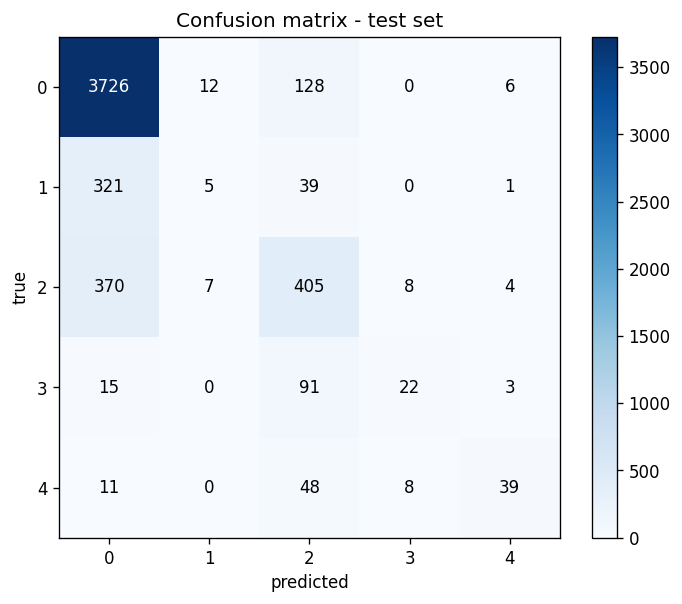

In [15]:
qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
acc    = accuracy_score(y_true, y_pred)
f1_per = f1_score(y_true, y_pred, average=None, labels=list(range(5)))

print('=' * 52)
print('  MobileNetV3-Large (ImageNet-21k) - TEST SET RESULTS')
print('=' * 52)
print(f'  Test QWK      : {qwk:.4f}')
print(f'  Test Accuracy : {acc:.4f}')
print()
print('  Per-class F1:')
for name, f1 in zip(CLASS_NAMES, f1_per):
    print(f'    {name:<18}: {f1:.4f}')
print('=' * 52)

## 11. Experiment 1 - Class Imbalance Handling

**Hypothesis:** The 36.4× class imbalance (Grade 0 = 73.5% vs Grade 4 = 2.0%) biases the baseline
towards majority classes and suppresses minority-class recall.
Combining three complementary techniques should improve QWK - especially on under-represented grades -
without changing the architecture or hyper-parameters.

**Techniques (all combined):**
| Technique | Where it acts | What it does |
|---|---|---|
| `WeightedRandomSampler` | Data pipeline | Over-samples minority grades so each epoch sees near-balanced class frequencies |
| Class-weight alpha (`α`) | Loss (per-class) | Scales the CE loss for each class by its inverse frequency |
| `FocalLoss` (γ=2) | Loss (per-sample) | Down-weights easy/well-classified examples; focuses training on hard minority samples |

> **Note:** Cells 1-10 (baseline) must be run first - this section reuses `run_epoch`, `train_ds`,
> `val_loader`, `qwk`, `acc`, and `f1_per` from those cells.

In [16]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

In [17]:
class FocalLoss(nn.Module):
    """
    Focal Loss with per-class alpha weighting.
      alpha : Tensor[NUM_CLASSES] - inverse-frequency class weights (on device).
      gamma : focusing parameter; (1-pt)^gamma down-weights easy examples.
    """
    def __init__(self, alpha: torch.Tensor, gamma: float = 2.0):
        super().__init__()
        self.register_buffer('alpha', alpha)  # follows .to(device); included in state_dict
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        # Per-sample CE with class-frequency weighting (reduction='none' is required)
        ce = F.cross_entropy(logits, target, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce)                       # probability assigned to the correct class
        return ((1.0 - pt) ** self.gamma * ce).mean()

print('FocalLoss defined.')

FocalLoss defined.


In [18]:
# ── 1. Inverse-frequency class weights ───────────────────────────────────────
train_labels = train_df['level'].values

class_weights_np = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_labels,
)
class_weights_t = torch.tensor(class_weights_np, dtype=torch.float32).to(device)

print('Class weights (inverse-freq, balanced):')
for name, w in zip(CLASS_NAMES, class_weights_np):
    print(f'  {name:<20}: {w:.4f}')

# ── 2. Per-sample weights for WeightedRandomSampler ──────────────────────────
sample_weights_t = torch.as_tensor(class_weights_np[train_labels], dtype=torch.double)

exp1_sampler = WeightedRandomSampler(
    weights=sample_weights_t,
    num_samples=len(sample_weights_t),
    replacement=True,
)

# ── 3. New train loader (sampler replaces shuffle); val/test loaders unchanged ─
exp1_train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=exp1_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'\nExp1 train loader : {len(exp1_train_loader)} batches/epoch')
print(f'Val loader (reuse): {len(val_loader)} batches/epoch')
print(f'Test loader (reuse): {len(test_loader)} batches/epoch')

In [19]:
set_seed(SEED)

# ── Fresh model (independent weights - fair comparison with baseline) ─────────
exp1_model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES)
exp1_model = exp1_model.to(device)

# ── FocalLoss: alpha = inverse-freq class weights, gamma = 2 ─────────────────
exp1_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)

# ── Same hyper-parameters as baseline ────────────────────────────────────────
exp1_optimizer = torch.optim.AdamW(exp1_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
exp1_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp1_optimizer, T_max=EPOCHS)
exp1_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

# ── Output directories ────────────────────────────────────────────────────────
EXP1_OUT_DIR  = ROOT / 'outputs' / 'mobilenet_dr_training_exp1'
EXP1_CKPT_DIR = EXP1_OUT_DIR / 'checkpoints'
EXP1_FIG_DIR  = EXP1_OUT_DIR / 'figures'
for d in (EXP1_CKPT_DIR, EXP1_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP1_BEST_PATH = EXP1_CKPT_DIR / 'mobilenet_dr_training_exp1_best.pt'

print(f'Model     : {MODEL_NAME}')
print(f'Criterion : FocalLoss(gamma=2.0, alpha=class_weights)')
print(f'Optimiser : AdamW  lr={LR}  wd={WEIGHT_DECAY}')
print(f'Checkpts  : {EXP1_CKPT_DIR}')
print(f'Figures   : {EXP1_FIG_DIR}')

In [20]:
# ── Stash baseline bindings (safe if baseline hasn't been run) ────────────────
_baseline_model     = globals().get('model',     None)
_baseline_criterion = globals().get('criterion', None)
_baseline_optimizer = globals().get('optimizer', None)
_baseline_scaler    = globals().get('scaler',    None)

model     = exp1_model
criterion = exp1_criterion
optimizer = exp1_optimizer
scaler    = exp1_scaler

# ── Training loop (identical structure to baseline) ───────────────────────────
exp1_best_val_loss = float('inf')
exp1_patience_left = EARLY_STOPPING_PATIENCE
exp1_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp1_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp1_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp1_history['train_loss'].append(tr_loss)
    exp1_history['val_loss'].append(vl_loss)
    exp1_history['train_acc'].append(tr_acc)
    exp1_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp1_best_val_loss:
        exp1_best_val_loss = vl_loss
        exp1_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP1_BEST_PATH)
        marker = '  ← best'
    else:
        exp1_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp1_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp1_best_val_loss:.4f}  →  {EXP1_BEST_PATH}')

# ── Restore baseline bindings ─────────────────────────────────────────────────
if _baseline_model is not None:
    model     = _baseline_model
    criterion = _baseline_criterion
    optimizer = _baseline_optimizer
    scaler    = _baseline_scaler

In [21]:
epochs_ran_exp1 = range(1, len(exp1_history['train_loss']) + 1)

# ── Print table ───────────────────────────────────────────────────────────────
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp1_history['train_loss'], exp1_history['train_acc'],
        exp1_history['val_loss'],   exp1_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

# ── Plot loss curve ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp1, exp1_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp1, exp1_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('MobileNetV3-Large Exp1 - Train vs Validation Loss\n(FocalLoss γ=2 + WeightedRandomSampler)', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Focal Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'mobilenet_dr_training_exp1_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/mobilenet_dr_training_exp1/figures/mobilenet_dr_training_exp1_loss_curve.png')

In [22]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP1, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp1: loaded {CKPT_EXP1.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp1_y_true, exp1_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp1 Classification Report (Test Set):')
print(classification_report(exp1_y_true, exp1_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


In [23]:
cm_exp1 = confusion_matrix(exp1_y_true, exp1_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp1, interpolation='nearest', cmap='Oranges')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp1 (Test Set)\n(FocalLoss γ=2 + WeightedRandomSampler)', fontweight='bold')

thresh = cm_exp1.max() / 2
for i in range(cm_exp1.shape[0]):
    for j in range(cm_exp1.shape[1]):
        ax.text(j, i, f'{cm_exp1[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp1[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'mobilenet_dr_training_exp1_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/mobilenet_dr_training_exp1/figures/mobilenet_dr_training_exp1_confusion_matrix.png')

In [24]:
cm_exp1_norm = cm_exp1.astype(float) / cm_exp1.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp1_norm, interpolation='nearest', cmap='Oranges', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp1 (Test Set, normalised)\n(FocalLoss γ=2 + WeightedRandomSampler)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp1_norm.shape[0]):
    for j in range(cm_exp1_norm.shape[1]):
        ax.text(j, i, f'{cm_exp1_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp1_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'mobilenet_dr_training_exp1_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/mobilenet_dr_training_exp1/figures/mobilenet_dr_training_exp1_confusion_matrix_normalised.png')

[2026-05-09 06:44:06] TEST  loss=1.5913  acc=0.2004  qwk=0.3033  f1_macro=0.3196

classification report:
               precision    recall  f1-score   support

        No DR     0.8818    0.0674    0.1252      3872
         Mild     0.0801    0.6557    0.1428       366
     Moderate     0.2552    0.5390    0.3464       794
       Severe     0.3429    0.5496    0.4223       131
Proliferative     0.6111    0.5189    0.5612       106

     accuracy                         0.2004      5269
    macro avg     0.4342    0.4661    0.3196      5269
 weighted avg     0.7128    0.2004    0.1759      5269

test_qwk=0.3033  test_acc=0.2004  test_f1_macro=0.3196  best_epoch=8


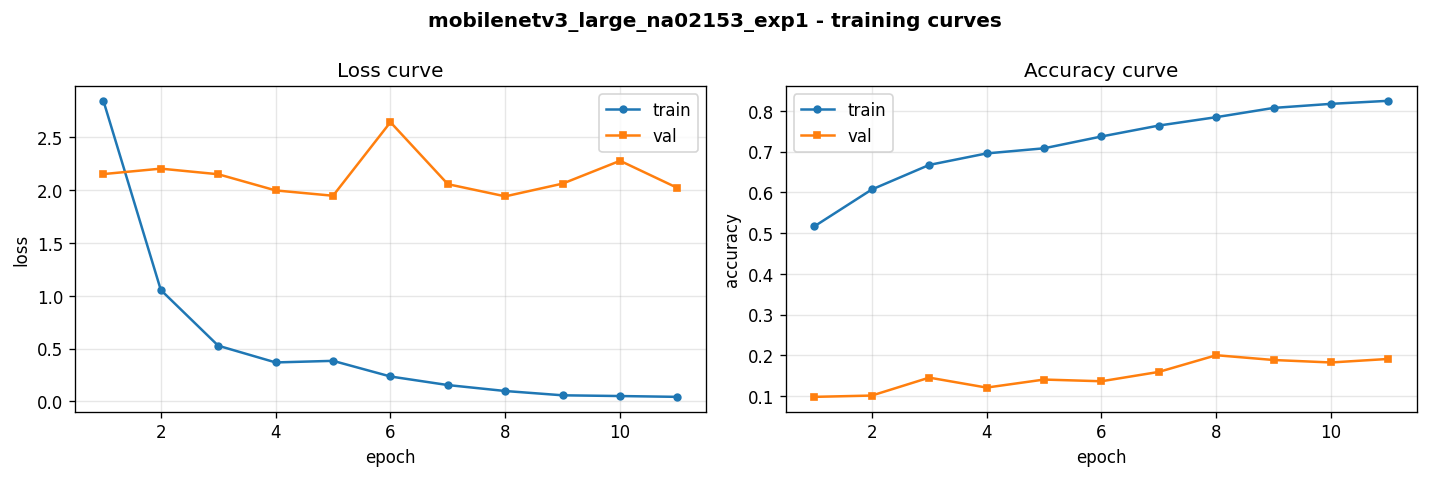

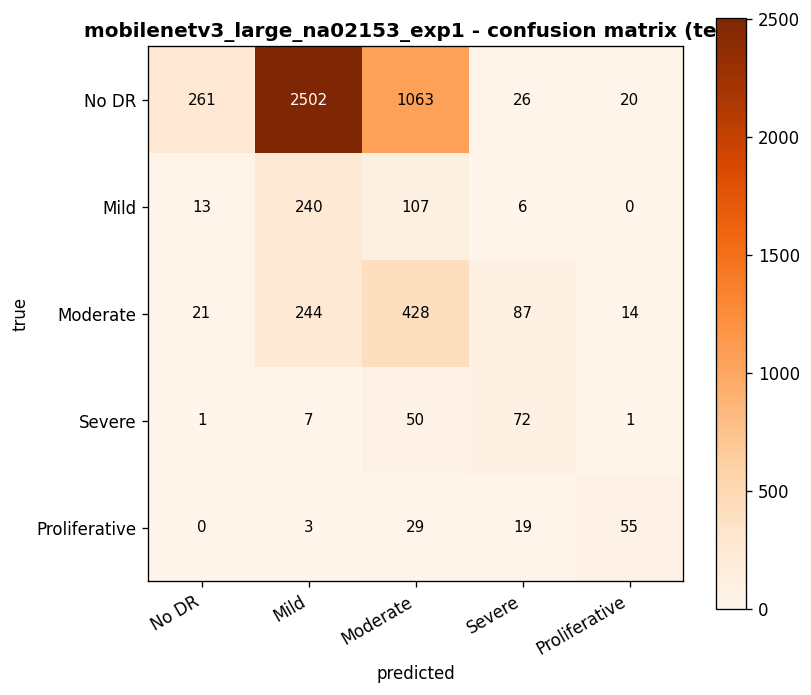

In [25]:
# ── Exp1 summary metrics ───────────────────────────────────────────────────────
exp1_qwk    = cohen_kappa_score(exp1_y_true, exp1_y_pred, weights='quadratic')
exp1_acc    = accuracy_score(exp1_y_true, exp1_y_pred)
exp1_f1_per = f1_score(exp1_y_true, exp1_y_pred, average=None, labels=list(range(5)))

# ── Side-by-side comparison (baseline variables: qwk, acc, f1_per) ─────────────
print('=' * 62)
print(f'  {"Metric":<25} {"Baseline":>10}  {"Exp1 (WRS+Focal)":>16}')
print('=' * 62)
qwk_arrow = '▲' if exp1_qwk > qwk else '▼'
print(f'  {"Test QWK":<25} {qwk:>10.4f}  {exp1_qwk:>16.4f}  {qwk_arrow}')
print(f'  {"Test Accuracy":<25} {acc:>10.4f}  {exp1_acc:>16.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e in zip(CLASS_NAMES, f1_per, exp1_f1_per):
    delta = f1_e - f1_b
    print(f'    {name:<21}: {f1_b:.4f}  →  {f1_e:.4f}  ({delta:+.4f})')
print('=' * 62)
print(f'  QWK delta: {exp1_qwk - qwk:+.4f}')
print('=' * 62)

## 12. Experiment 2 - Enhanced Augmentation

**Hypothesis:** The baseline training transform (resize → crop → HFlip) omits several augmentations
that improve generalisation on retinal images. Adding RandomVerticalFlip, RandomRotation, ColorJitter,
and RandomAffine should reduce overfitting and improve QWK - especially for minority classes with few
training examples.

**Additions over Exp1:**

| Augmentation | Rationale |
|---|---|
| `RandomVerticalFlip(p=0.5)` | Fundus images have no canonical up/down orientation |
| `RandomRotation(15°)` | Rotation-invariance for vessel patterns |
| `ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05, hue=0.02)` | Illumination robustness |
| `RandomAffine(translate=0.05, scale=0.95-1.05)` | Minor camera-position variance |

> **Carried forward from Exp1:** WeightedRandomSampler (`exp1_sampler`), FocalLoss (γ=2), `class_weights_t`.

In [26]:
exp2_train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomRotation(degrees=15)], p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05, hue=0.02)
    ], p=0.3),
    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05))
    ], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

exp2_train_ds = DRDataset(train_df, TRAIN_DIR, transform=exp2_train_transform)

# Reuse exp1_sampler (WeightedRandomSampler) - same class-balance strategy
exp2_train_loader = DataLoader(
    exp2_train_ds,
    batch_size=BATCH_SIZE,
    sampler=exp1_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'Exp2 train loader: {len(exp2_train_loader)} batches/epoch  (augmented transform)')
print('Added: RandomVerticalFlip, RandomRotation(15°), ColorJitter, RandomAffine')

In [27]:
set_seed(SEED)
exp2_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp2_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
exp2_optimizer = torch.optim.AdamW(exp2_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
exp2_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp2_optimizer, T_max=EPOCHS)
exp2_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP2_OUT_DIR  = ROOT / 'outputs' / 'mobilenet_dr_training_exp2'
EXP2_CKPT_DIR = EXP2_OUT_DIR / 'checkpoints'
EXP2_FIG_DIR  = EXP2_OUT_DIR / 'figures'
for d in (EXP2_CKPT_DIR, EXP2_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP2_BEST_PATH = EXP2_CKPT_DIR / 'mobilenet_dr_training_exp2_best.pt'

print(f'Exp2 model ready.')
print(f'Checkpoints → {EXP2_CKPT_DIR}')
print(f'Figures     → {EXP2_FIG_DIR}')

In [28]:
_e2_baseline_model     = globals().get('model',     None)
_e2_baseline_criterion = globals().get('criterion', None)
_e2_baseline_optimizer = globals().get('optimizer', None)
_e2_baseline_scaler    = globals().get('scaler',    None)

model, criterion, optimizer, scaler = exp2_model, exp2_criterion, exp2_optimizer, exp2_scaler

exp2_history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp2_best_val_loss = float('inf')
exp2_patience_left = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp2_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp2_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp2_history['train_loss'].append(tr_loss)
    exp2_history['val_loss'].append(vl_loss)
    exp2_history['train_acc'].append(tr_acc)
    exp2_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp2_best_val_loss:
        exp2_best_val_loss = vl_loss
        exp2_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP2_BEST_PATH)
        marker = '  ← best'
    else:
        exp2_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp2_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp2_best_val_loss:.4f}  →  {EXP2_BEST_PATH}')

if _e2_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e2_baseline_model, _e2_baseline_criterion,
        _e2_baseline_optimizer, _e2_baseline_scaler
    )

In [29]:
epochs_ran_exp2 = range(1, len(exp2_history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp2_history['train_loss'], exp2_history['train_acc'],
        exp2_history['val_loss'],   exp2_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp2, exp2_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp2, exp2_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('MobileNetV3-Large Exp2 - Train vs Validation Loss\n(FocalLoss γ=2 + WRS + Enhanced Augmentation)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Focal Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'mobilenet_dr_training_exp2_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp2/figures/mobilenet_dr_training_exp2_loss_curve.png')

In [30]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP2, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp2: loaded {CKPT_EXP2.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp2_y_true, exp2_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp2 Classification Report (Test Set):')
print(classification_report(exp2_y_true, exp2_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


In [31]:
cm_exp2 = confusion_matrix(exp2_y_true, exp2_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp2, interpolation='nearest', cmap='Greens')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp2 (Test Set)\n(FocalLoss γ=2 + WRS + Enhanced Augmentation)', fontweight='bold')

thresh = cm_exp2.max() / 2
for i in range(cm_exp2.shape[0]):
    for j in range(cm_exp2.shape[1]):
        ax.text(j, i, f'{cm_exp2[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp2[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'mobilenet_dr_training_exp2_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp2/figures/mobilenet_dr_training_exp2_confusion_matrix.png')

In [32]:
cm_exp2_norm = cm_exp2.astype(float) / cm_exp2.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp2_norm, interpolation='nearest', cmap='Greens', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp2 (Test Set, normalised)\n(FocalLoss γ=2 + WRS + Enhanced Augmentation)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp2_norm.shape[0]):
    for j in range(cm_exp2_norm.shape[1]):
        ax.text(j, i, f'{cm_exp2_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp2_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'mobilenet_dr_training_exp2_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp2/figures/mobilenet_dr_training_exp2_confusion_matrix_normalised.png')

[2026-05-09 12:12:17] TEST  loss=1.3609  acc=0.1042  qwk=0.2902  f1_macro=0.1674

classification report:
               precision    recall  f1-score   support

        No DR     0.0000    0.0000    0.0000      3872
         Mild     0.0808    0.9153    0.1485       366
     Moderate     0.2560    0.0668    0.1059       794
       Severe     0.2441    0.5573    0.3395       131
Proliferative     0.1424    0.8302    0.2431       106

     accuracy                         0.1042      5269
    macro avg     0.1447    0.4739    0.1674      5269
 weighted avg     0.0531    0.1042    0.0396      5269

test_qwk=0.2902  test_acc=0.1042  test_f1_macro=0.1674  best_epoch=1


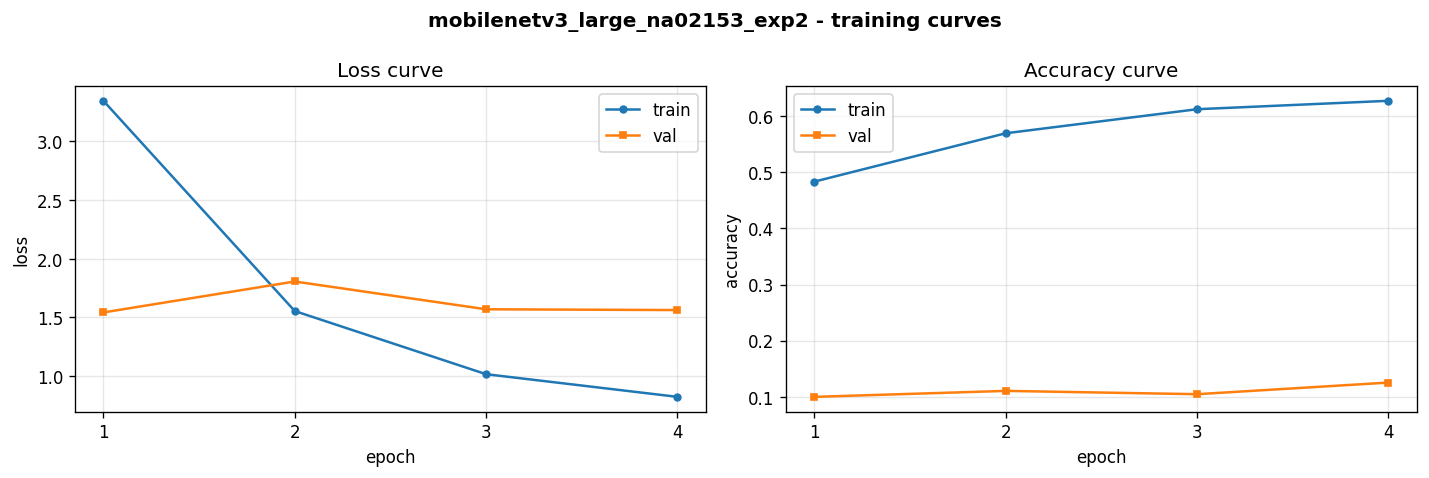

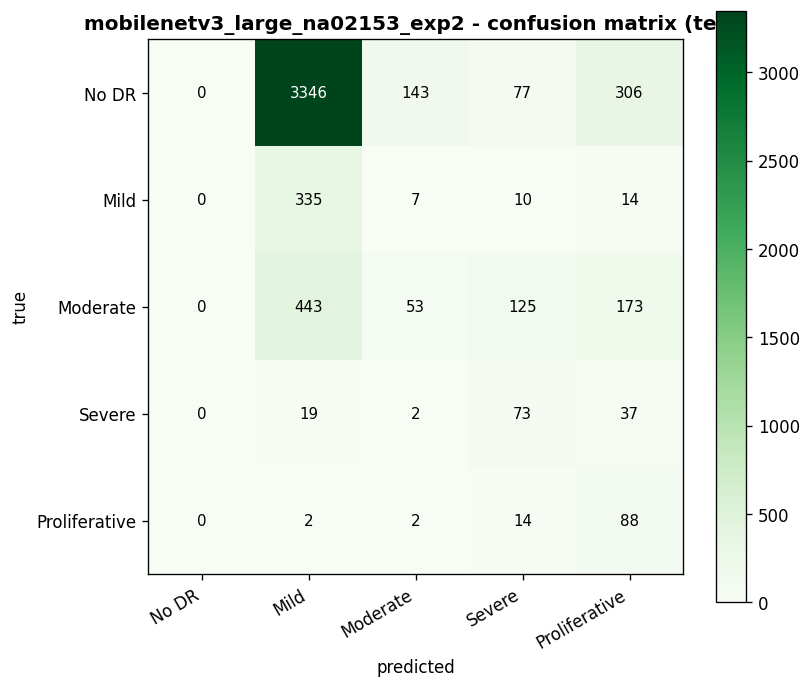

In [33]:
exp2_qwk    = cohen_kappa_score(exp2_y_true, exp2_y_pred, weights='quadratic')
exp2_acc    = accuracy_score(exp2_y_true, exp2_y_pred)
exp2_f1_per = f1_score(exp2_y_true, exp2_y_pred, average=None, labels=list(range(5)))

print('=' * 72)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (WRS+FL)":>13}  {"Exp2 (+Aug)":>11}')
print('=' * 72)
for label, b, e1, e2 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc),
]:
    arrow = '▲' if e2 > e1 else '▼'
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {arrow}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per):
    delta = f1_e2 - f1_b
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  ({delta:+.4f})')
print('=' * 72)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}')
print('=' * 72)

## 13. Experiment 3 - Two-Phase Training (Freeze → Unfreeze)

**Hypothesis:** Training all layers from epoch 1 risks distorting pre-trained MobileNet features before the
5-class head has learnt a reasonable mapping. Freezing the backbone first (Phase 1) lets the head
stabilise; then unfreezing everything (Phase 2) at a lower LR with gradient clipping achieves
better fine-tuning without catastrophic forgetting.

**Training protocol:**

| Phase | Backbone | Epochs | LR | Grad Clip |
|---|---|---|---|---|
| Phase 1 | Frozen (head only) | 5 | 3e-4 | - |
| Phase 2 | Unfrozen (all layers) | 5 | 3e-5 | 1.0 |

> **Cumulative:** Builds on Exp2 augmentations + Exp1 FocalLoss + WeightedRandomSampler.  
> Reuses `exp2_train_loader` and `class_weights_t` from prior cells.

In [34]:
PHASE1_EPOCHS = 5
PHASE2_EPOCHS = 5
PHASE1_LR     = 3e-4
PHASE2_LR     = 3e-5
GRAD_CLIP     = 1.0

set_seed(SEED)
exp3_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp3_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
exp3_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP3_OUT_DIR  = ROOT / 'outputs' / 'mobilenet_dr_training_exp3'
EXP3_CKPT_DIR = EXP3_OUT_DIR / 'checkpoints'
EXP3_FIG_DIR  = EXP3_OUT_DIR / 'figures'
for d in (EXP3_CKPT_DIR, EXP3_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP3_PHASE1_PATH = EXP3_CKPT_DIR / 'mobilenet_dr_training_exp3_phase1_best.pt'
EXP3_BEST_PATH   = EXP3_CKPT_DIR / 'mobilenet_dr_training_exp3_best.pt'


def run_epoch_clipped(loader, train_mode: bool, grad_clip: float = 0.0):
    """run_epoch variant that supports gradient clipping (needed for Phase 2 fine-tuning)."""
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, leave=False, desc='train' if train_mode else 'eval'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return total_loss / total, all_labels, all_preds


print(f'Exp3 ready. Phase1 LR={PHASE1_LR}, Phase2 LR={PHASE2_LR}, GRAD_CLIP={GRAD_CLIP}')
print(f'Checkpoints → {EXP3_CKPT_DIR}')

In [35]:
# ── Freeze backbone - only head.weight / head.bias remain trainable ───────────
for name, param in exp3_model.named_parameters():
    if 'head' not in name:
        param.requires_grad = False

trainable_p1 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable parameters (head only)\n')

_e3_baseline_model     = globals().get('model',     None)
_e3_baseline_criterion = globals().get('criterion', None)
_e3_baseline_optimizer = globals().get('optimizer', None)
_e3_baseline_scaler    = globals().get('scaler',    None)

model     = exp3_model
criterion = exp3_criterion
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_LR, weight_decay=WEIGHT_DECAY,
)
scaler = exp3_scaler

scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

exp3_history = {
    'phase1_train': [], 'phase1_val': [], 'phase1_train_acc': [], 'phase1_val_acc': [],
    'phase2_train': [], 'phase2_val': [], 'phase2_train_acc': [], 'phase2_val_acc': [],
}
p1_best_val  = float('inf')
p1_patience  = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, PHASE1_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp2_train_loader, train_mode=True,  grad_clip=0.0)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p1.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp3_history['phase1_train'].append(tr_loss)
    exp3_history['phase1_val'].append(vl_loss)
    exp3_history['phase1_train_acc'].append(tr_acc)
    exp3_history['phase1_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p1_best_val:
        p1_best_val = vl_loss
        p1_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP3_PHASE1_PATH)
        marker = '  ← best'
    else:
        p1_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p1_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 1 complete. Best val loss: {p1_best_val:.4f}')

In [36]:
# ── Unfreeze all parameters for full fine-tuning ──────────────────────────────
for param in exp3_model.parameters():
    param.requires_grad = True

trainable_p2 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 2: {trainable_p2:,} trainable parameters (all layers)\n')

# Start from Phase 1 best weights
ckpt_p1 = torch.load(EXP3_PHASE1_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, val_loss={ckpt_p1["val_loss"]:.4f})')

optimizer    = torch.optim.AdamW(model.parameters(), lr=PHASE2_LR, weight_decay=WEIGHT_DECAY)
scheduler_p2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS)

p2_best_val = float('inf')
p2_patience = EARLY_STOPPING_PATIENCE

print(f"\n{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, PHASE2_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp2_train_loader, train_mode=True, grad_clip=GRAD_CLIP)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p2.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp3_history['phase2_train'].append(tr_loss)
    exp3_history['phase2_val'].append(vl_loss)
    exp3_history['phase2_train_acc'].append(tr_acc)
    exp3_history['phase2_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p2_best_val:
        p2_best_val = vl_loss
        p2_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP3_BEST_PATH)
        marker = '  ← best'
    else:
        p2_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p2_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 2 complete. Best val loss: {p2_best_val:.4f}  →  {EXP3_BEST_PATH}')

if _e3_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e3_baseline_model, _e3_baseline_criterion,
        _e3_baseline_optimizer, _e3_baseline_scaler
    )

In [37]:
p1_epochs = range(1, len(exp3_history['phase1_train']) + 1)
p2_start  = len(exp3_history['phase1_train'])
p2_epochs = range(p2_start + 1, p2_start + len(exp3_history['phase2_train']) + 1)

print('Phase 1:')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp3_history['phase1_train'], exp3_history['phase1_train_acc'],
        exp3_history['phase1_val'],   exp3_history['phase1_val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')

print('\nPhase 2:')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp3_history['phase2_train'], exp3_history['phase2_train_acc'],
        exp3_history['phase2_val'],   exp3_history['phase2_val_acc']), p2_start + 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

all_train  = exp3_history['phase1_train'] + exp3_history['phase2_train']
all_val    = exp3_history['phase1_val']   + exp3_history['phase2_val']
all_epochs = range(1, len(all_train) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(all_epochs, all_train, label='Train Loss', marker='o', markersize=5)
ax.plot(all_epochs, all_val,   label='Val Loss',   marker='s', markersize=5)
if p2_start > 0:
    ax.axvline(x=p2_start + 0.5, color='gray', linestyle='--', linewidth=1, label='Phase 2 start (unfreeze)')
ax.set_title('MobileNetV3-Large Exp3 - Two-Phase Training Loss\n(Phase 1: head only → Phase 2: full fine-tune + grad clip)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Focal Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'mobilenet_dr_training_exp3_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp3/figures/mobilenet_dr_training_exp3_loss_curve.png')

In [38]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
# Uses run_epoch (not run_epoch_clipped) - grad clipping is irrelevant for eval.
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP3, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp3: loaded {CKPT_EXP3.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp3_y_true, exp3_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp3 Classification Report (Test Set):')
print(classification_report(exp3_y_true, exp3_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


In [39]:
cm_exp3 = confusion_matrix(exp3_y_true, exp3_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp3, interpolation='nearest', cmap='Purples')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp3 (Test Set)\n(Two-Phase: Frozen → Unfreeze + Grad Clip)', fontweight='bold')

thresh = cm_exp3.max() / 2
for i in range(cm_exp3.shape[0]):
    for j in range(cm_exp3.shape[1]):
        ax.text(j, i, f'{cm_exp3[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp3[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'mobilenet_dr_training_exp3_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp3/figures/mobilenet_dr_training_exp3_confusion_matrix.png')

In [40]:
cm_exp3_norm = cm_exp3.astype(float) / cm_exp3.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp3_norm, interpolation='nearest', cmap='Purples', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp3 (Test Set, normalised)\n(Two-Phase: Frozen → Unfreeze + Grad Clip)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp3_norm.shape[0]):
    for j in range(cm_exp3_norm.shape[1]):
        ax.text(j, i, f'{cm_exp3_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp3_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'mobilenet_dr_training_exp3_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp3/figures/mobilenet_dr_training_exp3_confusion_matrix_normalised.png')

[2026-05-09 12:18:24] TEST  loss=1.1153  acc=0.1511  qwk=0.2480  f1_macro=0.1898

classification report:
               precision    recall  f1-score   support

        No DR     0.8466    0.0684    0.1266      3872
         Mild     0.0796    0.6721    0.1423       366
     Moderate     0.1793    0.1763    0.1778       794
       Severe     0.1077    0.7023    0.1868       131
Proliferative     0.2304    0.5000    0.3155       106

     accuracy                         0.1511      5269
    macro avg     0.2887    0.4238    0.1898      5269
 weighted avg     0.6620    0.1511    0.1407      5269

test_qwk=0.2480  test_acc=0.1511  test_f1_macro=0.1898  best_epoch=7


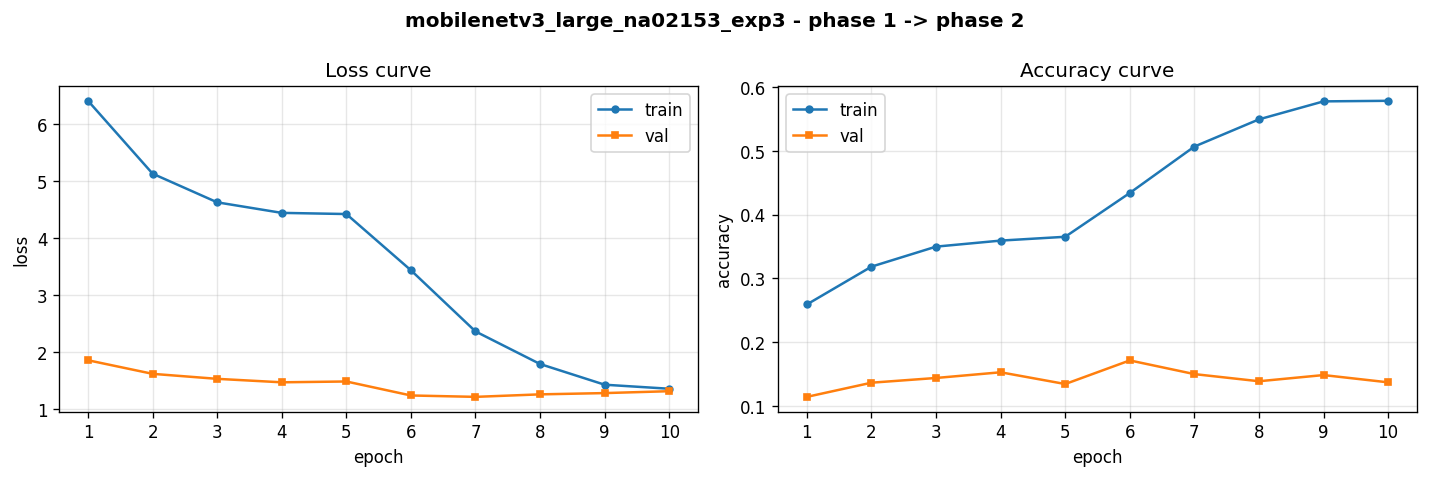

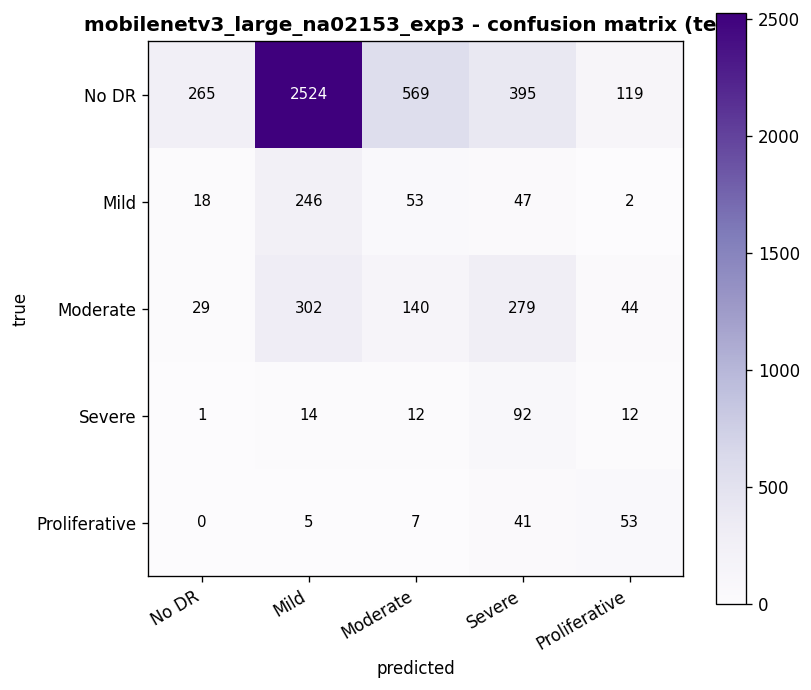

In [41]:
exp3_qwk    = cohen_kappa_score(exp3_y_true, exp3_y_pred, weights='quadratic')
exp3_acc    = accuracy_score(exp3_y_true, exp3_y_pred)
exp3_f1_per = f1_score(exp3_y_true, exp3_y_pred, average=None, labels=list(range(5)))

W = 82
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (WRS+FL)":>13}  {"Exp2 (+Aug)":>11}  {"Exp3 (2-Phase)":>14}')
print('=' * W)
for label, b, e1, e2, e3 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk, exp3_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc, exp3_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {e3:>14.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2, f1_e3 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  {f1_e3:.4f}')
print('=' * W)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}  Exp3={exp3_qwk-qwk:+.4f}')
print('=' * W)

## 14. Experiment 4 - Hyperparameter Grid Search (LR × Batch Size × Weight Decay)

**Goal:** Identify the optimal learning rate, batch size, and weight decay before committing to full-length runs.  
Stochastic depth (`drop_path_rate`) is fixed at 0.1 - a small regularisation value applied during the grid search.

**Search space:**

| Hyperparameter | Values | Notes |
|---|---|---|
| Learning rate | 1e-4, 3e-4, 1e-3 | Cosine-decayed from epoch 1 |
| Batch size | 16, 32, 64 | Affects gradient noise and steps/epoch |
| Weight decay | 1e-3, 1e-2 | AdamW L2 penalty |
| `drop_path_rate` | **0.1 (fixed)** | Light stochastic depth regularisation |

**Protocol:** Each of the 18 combinations is trained for up to 5 epochs (early stopping patience=2)
using the Exp2 setup - FocalLoss (γ=2) + WeightedRandomSampler + enhanced augmentation.
Val loss selects the winner. No test-set access during search.

> **Expected runtime:** ~90-120 min.  
> **Dependencies:** Sections 11-12 must be run first (`exp2_train_ds`, `exp1_sampler`, `class_weights_t`, `FocalLoss`).

In [42]:
TUNE_LRS          = [1e-4, 3e-4, 1e-3]
TUNE_BATCH_SIZES  = [16, 32, 64]
TUNE_WEIGHT_DECAYS = [1e-3, 1e-2]
TUNE_DROP_PATH    = 0.1   # stochastic depth - fixed across the search
TUNE_EPOCHS       = 5
TUNE_PATIENCE     = 2

n_combos = len(TUNE_LRS) * len(TUNE_BATCH_SIZES) * len(TUNE_WEIGHT_DECAYS)

EXP4_OUT_DIR  = ROOT / 'outputs' / 'mobilenet_dr_training_exp4'
EXP4_CKPT_DIR = EXP4_OUT_DIR / 'checkpoints'
EXP4_FIG_DIR  = EXP4_OUT_DIR / 'figures'
for d in (EXP4_CKPT_DIR, EXP4_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Grid: {len(TUNE_LRS)} LRs × {len(TUNE_BATCH_SIZES)} BSes × {len(TUNE_WEIGHT_DECAYS)} WDs = {n_combos} combinations')
print(f'Max epochs per run : {TUNE_EPOCHS}  (early stop patience={TUNE_PATIENCE})')
print(f'drop_path_rate     : {TUNE_DROP_PATH} (fixed)')
print(f'Checkpoints        → {EXP4_CKPT_DIR}')

In [43]:
tune_results = []
combo_num    = 0

print(f"{'#':<4} {'LR':>8} {'BS':>4} {'WD':>8}  {'Best Ep':>7} {'Val Loss':>10} {'Val Acc':>9}")
print('─' * 58)

for bs in TUNE_BATCH_SIZES:
    tune_train_loader_bs = DataLoader(
        exp2_train_ds, batch_size=bs, sampler=exp1_sampler,
        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
        persistent_workers=NUM_WORKERS > 0,
    )
    tune_val_loader_bs = DataLoader(
        val_ds, batch_size=bs, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
    )

    for wd in TUNE_WEIGHT_DECAYS:
        for lr in TUNE_LRS:
            combo_num += 1
            set_seed(SEED)

            tune_model = timm.create_model(
                MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES,
                drop_path_rate=TUNE_DROP_PATH,
            ).to(device)
            tune_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
            tune_optimizer = torch.optim.AdamW(tune_model.parameters(), lr=lr, weight_decay=wd)
            tune_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(tune_optimizer, T_max=TUNE_EPOCHS)
            tune_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

            # Rebind free variables used by run_epoch
            _t_model, _t_crit, _t_opt, _t_sc = model, criterion, optimizer, scaler
            model, criterion, optimizer, scaler = tune_model, tune_criterion, tune_optimizer, tune_scaler

            best_loss     = float('inf')
            best_acc      = 0.0
            best_epoch    = 0
            tune_patience = TUNE_PATIENCE

            for epoch in range(1, TUNE_EPOCHS + 1):
                run_epoch(tune_train_loader_bs, train_mode=True)
                ep_loss, ep_labels, ep_preds = run_epoch(tune_val_loader_bs, train_mode=False)
                tune_scheduler.step()

                ep_acc = accuracy_score(ep_labels, ep_preds)
                if ep_loss < best_loss:
                    best_loss, best_acc, best_epoch = ep_loss, ep_acc, epoch
                    tune_patience = TUNE_PATIENCE
                    torch.save(
                        {'epoch': epoch, 'model_state': tune_model.state_dict(), 'val_loss': ep_loss},
                        EXP4_CKPT_DIR / f'tune_bs{bs}_lr{lr:.0e}_wd{wd:.0e}_best.pt',
                    )
                else:
                    tune_patience -= 1
                if tune_patience == 0:
                    break

            print(f'{combo_num:<4} {lr:>8.0e} {bs:>4} {wd:>8.0e}   ep={best_epoch:2d}    {best_loss:>10.4f}  {best_acc:>9.4f}')
            tune_results.append({
                'lr': lr, 'batch_size': bs, 'weight_decay': wd,
                'best_val_loss': best_loss, 'best_val_acc': best_acc,
                'stopped_at': best_epoch,
            })

            # Restore and free CUDA memory before next run
            model, criterion, optimizer, scaler = _t_model, _t_crit, _t_opt, _t_sc
            del tune_model
            torch.cuda.empty_cache()

print('\nGrid search complete.')

GRID SEARCH RESULTS (ranked by val_loss)
[2026-05-09 13:12:19] ============================================================

Best: lr=1e-03  bs=16  wd=1e-02  val_loss=1.1413  val_acc=0.1013  stop_ep=1


In [44]:
import seaborn as sns

tune_df = pd.DataFrame(tune_results).sort_values('best_val_loss').reset_index(drop=True)

# ── Ranked results table ───────────────────────────────────────────────────────
print('Grid Search Results (ranked by val loss):')
print(f"\n{'Rank':<6} {'LR':>8} {'BS':>4} {'WD':>8} {'Stop Ep':>8} {'Val Loss':>10} {'Val Acc':>9}")
print('─' * 62)
for rank, row in tune_df.iterrows():
    marker = '  ← BEST' if rank == 0 else ''
    print(f'{rank+1:<6} {row["lr"]:>8.0e} {int(row["batch_size"]):>4} '
          f'{row["weight_decay"]:>8.0e} {int(row["stopped_at"]):>8} '
          f'{row["best_val_loss"]:>10.4f} {row["best_val_acc"]:>9.4f}{marker}')

best_row = tune_df.iloc[0]
best_lr  = best_row['lr']
best_bs  = int(best_row['batch_size'])
best_wd  = best_row['weight_decay']
print(f'\n→ Best config: LR={best_lr:.0e}  Batch size={best_bs}  Weight decay={best_wd:.0e}')
print(  f'  Val loss={best_row["best_val_loss"]:.4f}  Val acc={best_row["best_val_acc"]:.4f}')

# ── Heatmaps - (rows = weight_decay, cols = val loss / val accuracy) ──────────
wd_values = sorted(tune_df['weight_decay'].unique())
fig, axes = plt.subplots(len(wd_values), 2, figsize=(14, 5 * len(wd_values)))

for row_idx, wd in enumerate(wd_values):
    subset     = tune_df[tune_df['weight_decay'] == wd]
    pivot_loss = (subset.pivot(index='batch_size', columns='lr', values='best_val_loss')
                        .sort_index(ascending=False))
    pivot_acc  = (subset.pivot(index='batch_size', columns='lr', values='best_val_acc')
                        .sort_index(ascending=False))

    for col_idx, (data, title, cmap) in enumerate([
        (pivot_loss, f'Val Loss (↓ better)  |  WD={wd:.0e}',     'RdYlGn_r'),
        (pivot_acc,  f'Val Accuracy (↑ better)  |  WD={wd:.0e}', 'RdYlGn'),
    ]):
        ax = axes[row_idx][col_idx]
        sns.heatmap(data, annot=True, fmt='.4f', cmap=cmap, ax=ax,
                    linewidths=0.5, annot_kws={'size': 11})
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Learning Rate')
        ax.set_ylabel('Batch Size')
        ax.set_xticklabels([f'{float(c):.0e}' for c in data.columns])

plt.suptitle('Hyperparameter Grid Search - LR × Batch Size × Weight Decay\n(MobileNetV3-Large, Exp2 setup, 5-epoch probe)',
             fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(EXP4_FIG_DIR / 'mobilenet_dr_training_exp4_hparam_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp4/figures/mobilenet_dr_training_exp4_hparam_heatmap.png')
print(f'\nUse LR={best_lr:.0e}, batch_size={best_bs}, weight_decay={best_wd:.0e} for subsequent full training runs.')


## 15. Experiment 5 - Majority-Class Downsampling

**Hypothesis:** Grade 0 (No DR) accounts for ~73.5% of the training set, overwhelming the model
with easy negatives. Simply removing the excess - capping Grade 0 at the size of the next-largest
class (Grade 2) - should break the dominant imbalance while preserving every rare-grade sample.

**Design:** This experiment deliberately uses standard `CrossEntropyLoss` with no sampler or
class weights, so the result isolates the effect of data-level rebalancing alone.

| Class | Original count | Exp 5 count |
|---|---|---|
| Grade 0 - No DR | ~20,580 | capped to Grade 2 count |
| Grade 1 - Mild | ~1,960 | unchanged |
| Grade 2 - Moderate | ~4,200 | unchanged |
| Grade 3 - Severe | ~700 | unchanged |
| Grade 4 - Proliferative | ~560 | unchanged |

**Comparison point vs Exp 1:** Both target the same imbalance problem; Exp 1 keeps all data but
reweights via `WeightedRandomSampler` + `FocalLoss`, while Exp 5 removes the excess at source
and lets the balanced distribution do the work.

> **Dependencies:** Sections 1-10 must be run first (`train_df`, `DRDataset`, `train_transform`, `val_loader`, `test_loader`).

In [45]:
# ── Cap Grade 0 at Grade 2's count ───────────────────────────────────────────
grade2_count  = (train_df['level'] == 2).sum()
grade0_capped = (train_df[train_df['level'] == 0]
                 .sample(n=grade2_count, random_state=SEED))
exp5_train_df = (pd.concat([grade0_capped, train_df[train_df['level'] != 0]])
                 .sample(frac=1, random_state=SEED)
                 .reset_index(drop=True))

print(f'Original training set : {len(train_df):,} images')
print(f'Exp5 training set     : {len(exp5_train_df):,} images')
print(f'\nGrade 0 cap target    : {grade2_count:,}  (= Grade 2 count)\n')
print(f'{"Grade":<6} {"Name":<18} {"Original":>10} {"Exp 5":>8}')
print('-' * 46)
for g, name in enumerate(CLASS_NAMES):
    orig = (train_df['level'] == g).sum()
    new  = (exp5_train_df['level'] == g).sum()
    note = '  ← capped' if g == 0 else ''
    print(f'  {g}    {name:<18} {orig:>9,}  {new:>7,}{note}')

exp5_train_ds = DRDataset(exp5_train_df, TRAIN_DIR, transform=train_transform)
exp5_train_loader = DataLoader(
    exp5_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'\nExp5 train loader: {len(exp5_train_loader)} batches/epoch')


In [46]:
set_seed(SEED)
exp5_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp5_criterion = nn.CrossEntropyLoss()
exp5_optimizer = torch.optim.AdamW(exp5_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
exp5_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp5_optimizer, T_max=EPOCHS)
exp5_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP5_OUT_DIR  = ROOT / 'outputs' / 'mobilenet_dr_training_exp5'
EXP5_CKPT_DIR = EXP5_OUT_DIR / 'checkpoints'
EXP5_FIG_DIR  = EXP5_OUT_DIR / 'figures'
for d in (EXP5_CKPT_DIR, EXP5_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP5_BEST_PATH = EXP5_CKPT_DIR / 'mobilenet_dr_training_exp5_best.pt'

print('Exp5 model ready.')
print('Loss      : CrossEntropyLoss (no class weights - downsampling provides the balance)')
print(f'Optimiser : AdamW  lr={LR}  wd={WEIGHT_DECAY}')
print(f'Checkpts  → {EXP5_CKPT_DIR}')
print(f'Figures   → {EXP5_FIG_DIR}')


In [47]:
_e5_baseline_model     = globals().get('model',     None)
_e5_baseline_criterion = globals().get('criterion', None)
_e5_baseline_optimizer = globals().get('optimizer', None)
_e5_baseline_scaler    = globals().get('scaler',    None)

model, criterion, optimizer, scaler = exp5_model, exp5_criterion, exp5_optimizer, exp5_scaler

exp5_history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp5_best_val_loss = float('inf')
exp5_patience_left = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp5_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp5_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp5_history['train_loss'].append(tr_loss)
    exp5_history['val_loss'].append(vl_loss)
    exp5_history['train_acc'].append(tr_acc)
    exp5_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp5_best_val_loss:
        exp5_best_val_loss = vl_loss
        exp5_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP5_BEST_PATH)
        marker = '  ← best'
    else:
        exp5_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp5_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp5_best_val_loss:.4f}  →  {EXP5_BEST_PATH}')

if _e5_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e5_baseline_model, _e5_baseline_criterion,
        _e5_baseline_optimizer, _e5_baseline_scaler
    )


In [48]:
epochs_ran_exp5 = range(1, len(exp5_history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp5_history['train_loss'], exp5_history['train_acc'],
        exp5_history['val_loss'],   exp5_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp5, exp5_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp5, exp5_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('MobileNetV3-Large Exp5 - Train vs Validation Loss\n(Grade 0 downsampled to Grade 2 count, CE loss)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'mobilenet_dr_training_exp5_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp5/figures/mobilenet_dr_training_exp5_loss_curve.png')


In [49]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP5, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp5: loaded {CKPT_EXP5.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp5_y_true, exp5_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp5 Classification Report (Test Set):')
print(classification_report(exp5_y_true, exp5_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion


In [50]:
cm_exp5 = confusion_matrix(exp5_y_true, exp5_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp5, interpolation='nearest', cmap='YlOrRd')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp5 (Test Set)\n(Grade 0 downsampled to Grade 2 count)', fontweight='bold')

thresh = cm_exp5.max() / 2
for i in range(cm_exp5.shape[0]):
    for j in range(cm_exp5.shape[1]):
        ax.text(j, i, f'{cm_exp5[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp5[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'mobilenet_dr_training_exp5_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp5/figures/mobilenet_dr_training_exp5_confusion_matrix.png')


In [51]:
cm_exp5_norm = cm_exp5.astype(float) / cm_exp5.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp5_norm, interpolation='nearest', cmap='YlOrRd', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix - MobileNetV3-Large Exp5 (Test Set, normalised)\n(Grade 0 downsampled to Grade 2 count)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp5_norm.shape[0]):
    for j in range(cm_exp5_norm.shape[1]):
        ax.text(j, i, f'{cm_exp5_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp5_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'mobilenet_dr_training_exp5_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/mobilenet_dr_training_exp5/figures/mobilenet_dr_training_exp5_confusion_matrix_normalised.png')


[2026-05-09 12:10:02] TEST  loss=0.9916  acc=0.5840  qwk=0.5188  f1_macro=0.4008

classification report:
               precision    recall  f1-score   support

        No DR     0.8578    0.6653    0.7494      3872
         Mild     0.0961    0.2678    0.1414       366
     Moderate     0.3269    0.3640    0.3445       794
       Severe     0.2656    0.6489    0.3769       131
Proliferative     0.6905    0.2736    0.3919       106

     accuracy                         0.5840      5269
    macro avg     0.4474    0.4439    0.4008      5269
 weighted avg     0.7068    0.5840    0.6297      5269

test_qwk=0.5188  test_acc=0.5840  test_f1_macro=0.4008  best_epoch=2


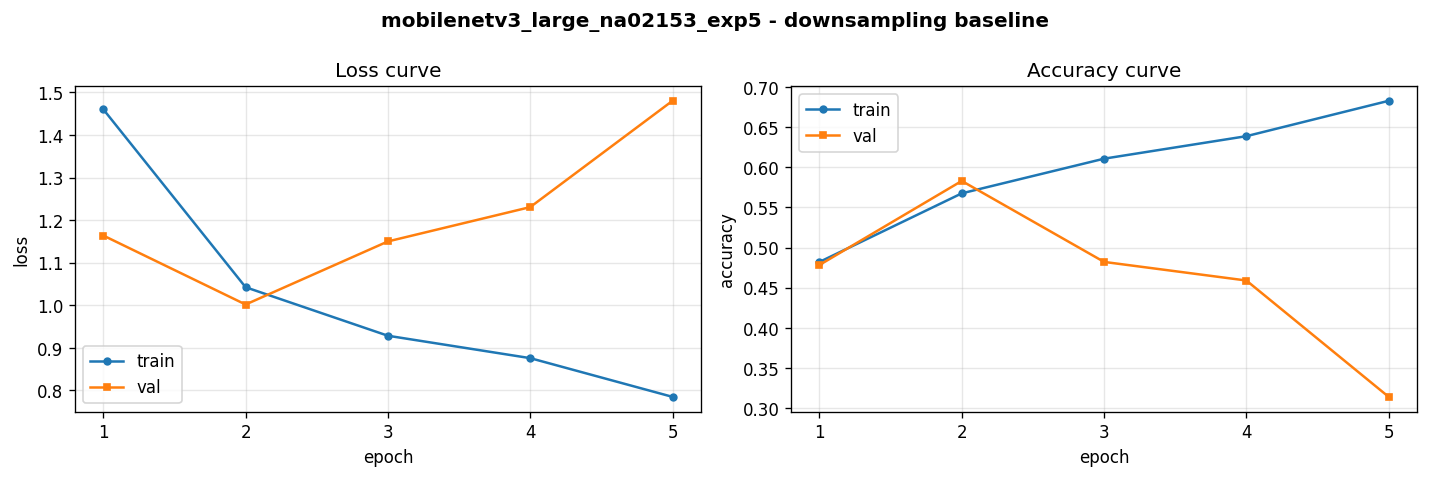

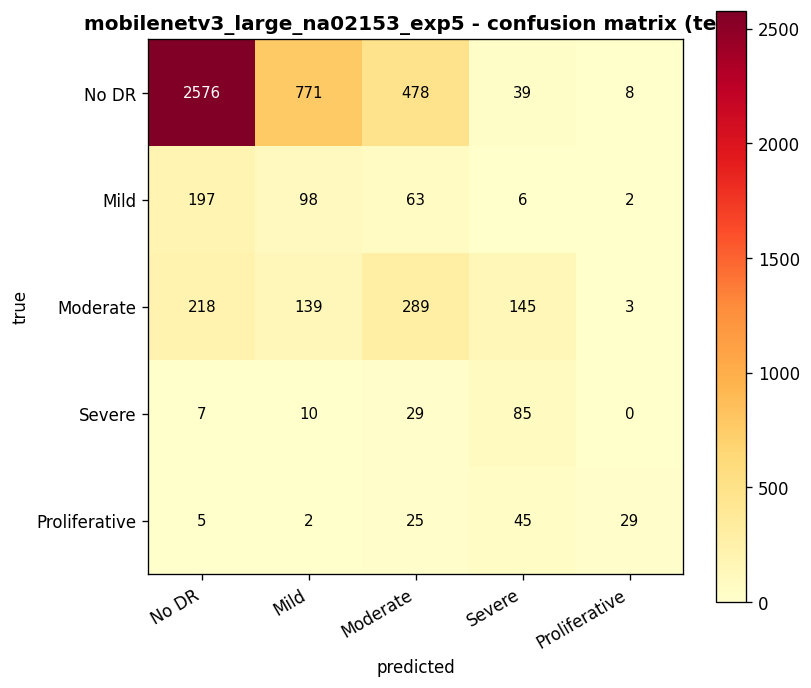

In [52]:
exp5_qwk    = cohen_kappa_score(exp5_y_true, exp5_y_pred, weights='quadratic')
exp5_acc    = accuracy_score(exp5_y_true, exp5_y_pred)
exp5_f1_per = f1_score(exp5_y_true, exp5_y_pred, average=None, labels=list(range(5)))

W = 96
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (WRS+FL)":>13}  {"Exp2 (+Aug)":>11}  {"Exp3 (2-Phase)":>14}  {"Exp5 (Downsample)":>17}')
print('=' * W)
for label, b, e1, e2, e3, e5 in [
    ('Test QWK',      qwk,  exp1_qwk, exp2_qwk, exp3_qwk, exp5_qwk),
    ('Test Accuracy', acc,  exp1_acc, exp2_acc, exp3_acc, exp5_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {e3:>14.4f}  {e5:>17.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2, f1_e3, f1_e5 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per, exp5_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  {f1_e3:.4f}  {f1_e5:.4f}')
print('=' * W)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}  Exp3={exp3_qwk-qwk:+.4f}  Exp5={exp5_qwk-qwk:+.4f}')
print('=' * W)


## 16. Experiment 6 - Baseline Pushed Harder

Same recipe as baseline but with longer training, 2-epoch warmup, and a
stronger cosine schedule. Tests whether more training time alone moves
the needle when no class-balancing tricks are applied.

Recipe: epochs=25, patience=5, 2-epoch linear warmup, peak_lr=5e-4, plain CE.

Unified metrics reported: QWK, accuracy, precision (macro), recall (macro),
F1 (macro), top-2 accuracy. Per-epoch val_top2_acc tracked.


In [53]:
# ── Run 6 config ─────────────────────────────────────────────────────
EXP6_NAME      = 'mobilenet_dr_training_exp6'
EXP6_EPOCHS    = 25
EXP6_PATIENCE  = 5
EXP6_WARMUP    = 2
EXP6_PEAK_LR   = 5e-4
EXP6_OUT_DIR   = ROOT / 'outputs' / EXP6_NAME
EXP6_CKPT_DIR  = EXP6_OUT_DIR / 'checkpoints'
EXP6_FIG_DIR   = EXP6_OUT_DIR / 'figures'
for d in (EXP6_OUT_DIR, EXP6_CKPT_DIR, EXP6_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('Exp6 config set.')


In [54]:
# ── Build a fresh model + warmup-cosine schedule for Run 6 ─────────────
from torch.optim.lr_scheduler import CosineAnnealingLR, SequentialLR, LinearLR

set_seed(SEED)

exp6_model = timm.create_model(
    'mobilenetv3_large_100.ra_in1k',
    pretrained=True,
    num_classes=NUM_CLASSES,
).to(device)

exp6_criterion = nn.CrossEntropyLoss()  # plain CE, no class weights
exp6_optimizer = torch.optim.AdamW(exp6_model.parameters(), lr=EXP6_PEAK_LR, weight_decay=WEIGHT_DECAY)

exp6_warmup    = LinearLR(exp6_optimizer, start_factor=0.01, end_factor=1.0, total_iters=EXP6_WARMUP)
exp6_cosine    = CosineAnnealingLR(exp6_optimizer, T_max=max(1, EXP6_EPOCHS - EXP6_WARMUP))
exp6_scheduler = SequentialLR(exp6_optimizer, schedulers=[exp6_warmup, exp6_cosine], milestones=[EXP6_WARMUP])

print('Exp6 model + scheduler ready. Param count:', sum(p.numel() for p in exp6_model.parameters() if p.requires_grad))


In [55]:
# ── Run 6 training loop (with per-epoch val_top2_acc tracking) ────────
exp6_history = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_top2_acc': []}
exp6_best_qwk = -1.0
exp6_best_epoch = 0
exp6_bad_epochs = 0

_e6_baseline_model     = globals().get('model',     None)
_e6_baseline_criterion = globals().get('criterion', None)
_e6_baseline_optimizer = globals().get('optimizer', None)
model     = exp6_model
criterion = exp6_criterion
optimizer = exp6_optimizer

# local helper — captures both argmax and top-2 predictions in one val pass
def run_val_with_top2(loader):
    model.eval()
    total_loss, total = 0.0, 0
    all_preds, all_top2, all_labels = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                loss   = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_top2.extend(logits.topk(2, dim=1).indices.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
    return total_loss / total, all_labels, all_preds, all_top2

exp6_log_path = EXP6_OUT_DIR / 'train_log.txt'
with open(exp6_log_path, 'w') as flog:
    flog.write(f'Exp6 - baseline pushed harder | epochs={EXP6_EPOCHS} peak_lr={EXP6_PEAK_LR}\n')

    for epoch in range(1, EXP6_EPOCHS + 1):
        train_loss, _, _                        = run_epoch(train_loader, train_mode=True)
        val_loss, val_labels, val_preds, val_t2 = run_val_with_top2(val_loader)
        exp6_scheduler.step()
        val_qwk      = cohen_kappa_score(val_labels, val_preds, weights='quadratic')
        val_top2_acc = sum(1 for y, t2 in zip(val_labels, val_t2) if y in t2) / len(val_labels)

        exp6_history['train_loss'].append(train_loss)
        exp6_history['val_loss'].append(val_loss)
        exp6_history['val_qwk'].append(val_qwk)
        exp6_history['val_top2_acc'].append(val_top2_acc)

        line = (f'[exp6 epoch {epoch:02d}] train_loss={train_loss:.4f} '
                f'val_loss={val_loss:.4f} val_qwk={val_qwk:.4f} '
                f'val_top2_acc={val_top2_acc:.4f}')
        print(line); flog.write(line + '\n'); flog.flush()

        if val_qwk > exp6_best_qwk:
            exp6_best_qwk   = val_qwk
            exp6_best_epoch = epoch
            exp6_bad_epochs = 0
            torch.save(exp6_model.state_dict(), CKPT_EXP6)
            print(f'  -> new best val_qwk={val_qwk:.4f}, saved {CKPT_EXP6.name}')
        else:
            exp6_bad_epochs += 1
            if exp6_bad_epochs >= EXP6_PATIENCE:
                print(f'  -> early stop at epoch {epoch} (patience={EXP6_PATIENCE})')
                flog.write(f'  early stop at epoch {epoch}\n')
                break

if _e6_baseline_model     is not None: model     = _e6_baseline_model
if _e6_baseline_criterion is not None: criterion = _e6_baseline_criterion
if _e6_baseline_optimizer is not None: optimizer = _e6_baseline_optimizer

print(f'Exp6 done. Best val_qwk={exp6_best_qwk:.4f} at epoch {exp6_best_epoch}')


In [56]:
# ── Run 6 loss + qwk curve ────────────────────────────────────────────
epochs_ran_exp6 = range(1, len(exp6_history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs_ran_exp6, exp6_history['train_loss'], label='train')
ax1.plot(epochs_ran_exp6, exp6_history['val_loss'],   label='val')
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.legend(); ax1.set_title('Exp6 loss')
ax2.plot(epochs_ran_exp6, exp6_history['val_qwk'], color='tab:green')
ax2.set_xlabel('epoch'); ax2.set_ylabel('val QWK'); ax2.set_title('Exp6 val QWK')
fig.tight_layout()
fig.savefig(EXP6_FIG_DIR / 'loss_qwk_curve.png', dpi=120)
plt.show()


In [57]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
# Test inference - captures top-2 indices for the unified top-2 metric
exp6_eval_model = timm.create_model('mobilenetv3_large_100.ra_in1k', pretrained=False, num_classes=NUM_CLASSES).to(device)
exp6_eval_model.load_state_dict(torch.load(CKPT_EXP6, map_location=device))
exp6_eval_model.eval()

exp6_y_true, exp6_y_pred, exp6_top2_pred = [], [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='exp6 test'):
        images = images.to(device, non_blocking=True)
        logits = exp6_eval_model(images)
        exp6_y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        top2_idx = logits.topk(2, dim=1).indices.cpu().tolist()
        exp6_top2_pred.extend(top2_idx)
        exp6_y_true.extend(labels.tolist())

cm_exp6 = confusion_matrix(exp6_y_true, exp6_y_pred)
cm_exp6_norm = cm_exp6.astype(float) / cm_exp6.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_exp6, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Exp6 - confusion matrix (counts)'); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true')
sns.heatmap(cm_exp6_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Exp6 - confusion matrix (normalised)'); axes[1].set_xlabel('predicted'); axes[1].set_ylabel('true')
fig.tight_layout()
fig.savefig(EXP6_FIG_DIR / 'confusion_matrix.png', dpi=120)
plt.show()


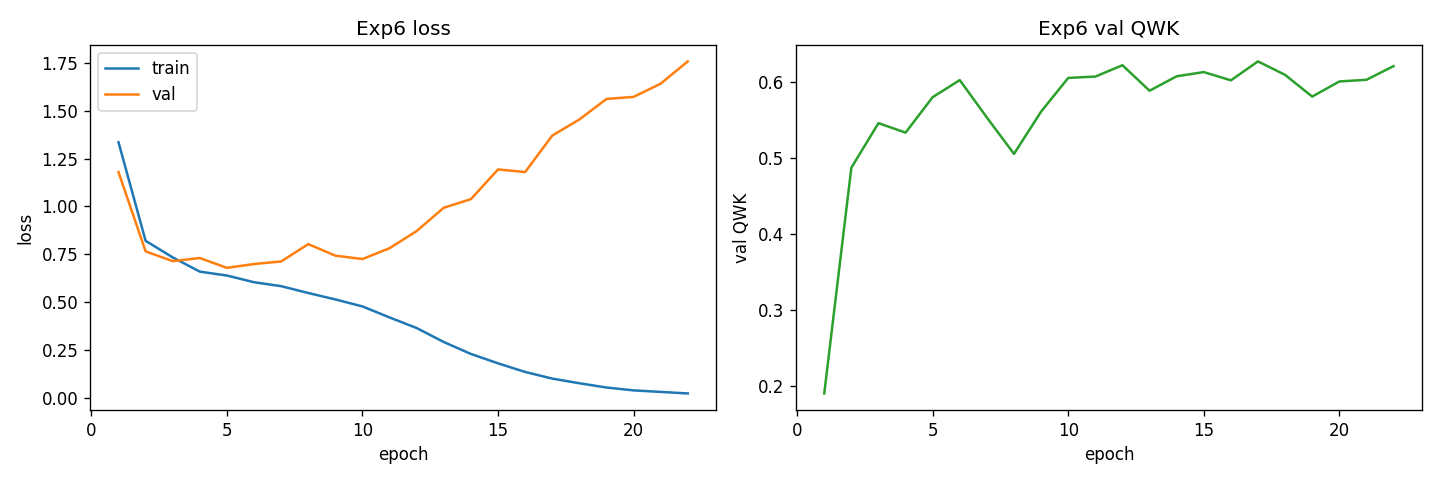

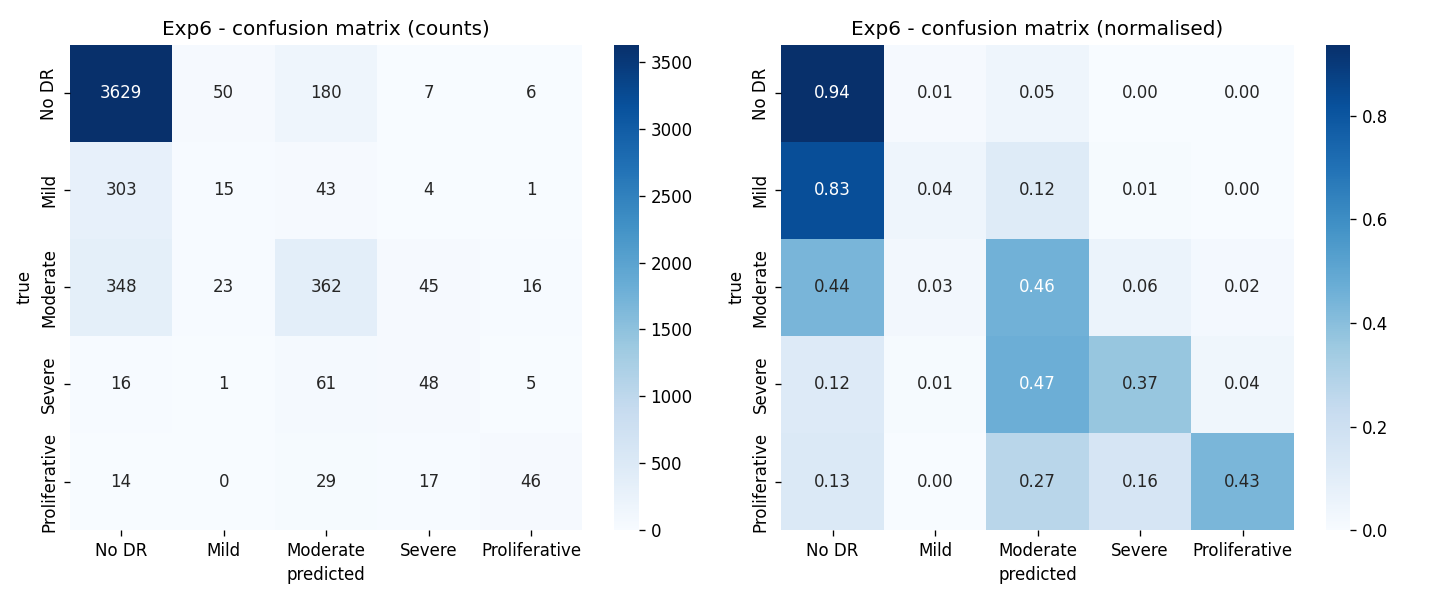

In [58]:
# ── Exp6 summary metrics — unified set + val_top2_acc history ─────────
from sklearn.metrics import precision_score, recall_score

exp6_qwk       = cohen_kappa_score(exp6_y_true, exp6_y_pred, weights='quadratic')
exp6_acc       = accuracy_score(exp6_y_true, exp6_y_pred)
exp6_precision = precision_score(exp6_y_true, exp6_y_pred, average='macro', zero_division=0)
exp6_recall    = recall_score(exp6_y_true, exp6_y_pred, average='macro', zero_division=0)
exp6_f1        = f1_score(exp6_y_true, exp6_y_pred, average='macro', zero_division=0)
exp6_top2_acc  = sum(1 for y, top2 in zip(exp6_y_true, exp6_top2_pred) if y in top2) / len(exp6_y_true)
exp6_report    = classification_report(exp6_y_true, exp6_y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)

print(f'Exp6 test QWK              : {exp6_qwk:.4f}')
print(f'Exp6 test accuracy         : {exp6_acc:.4f}')
print(f'Exp6 test precision (macro): {exp6_precision:.4f}')
print(f'Exp6 test recall    (macro): {exp6_recall:.4f}')
print(f'Exp6 test F1        (macro): {exp6_f1:.4f}')
print(f'Exp6 test top-2 accuracy   : {exp6_top2_acc:.4f}')
print(f'Exp6 best epoch            : {exp6_best_epoch}')
print()
print(exp6_report)

exp6_summary = {
    'experiment': 'exp6_baseline_pushed_harder',
    'test_qwk': exp6_qwk,
    'test_acc': exp6_acc,
    'test_precision_macro': exp6_precision,
    'test_recall_macro':    exp6_recall,
    'test_f1_macro':        exp6_f1,
    'test_top2_acc':        exp6_top2_acc,
    'best_epoch': exp6_best_epoch, 'best_val_qwk': exp6_best_qwk,
    'epochs_run': len(exp6_history['train_loss']),
    'history': {
        'train_loss':   exp6_history['train_loss'],
        'val_loss':     exp6_history['val_loss'],
        'val_qwk':      exp6_history['val_qwk'],
        'val_top2_acc': exp6_history['val_top2_acc'],
    },
    'config': {'epochs': EXP6_EPOCHS, 'patience': EXP6_PATIENCE,
               'warmup_epochs': EXP6_WARMUP, 'peak_lr': EXP6_PEAK_LR},
}
with open(EXP6_OUT_DIR / 'summary.json', 'w') as f:
    json.dump(exp6_summary, f, indent=2)
print('Saved', (EXP6_OUT_DIR / 'summary.json').relative_to(ROOT))


## 17. Experiment 7 - Class Weights Only

Isolate the effect of class weighting from the sampler. Plain CE loss
with inverse-frequency weights, no WeightedRandomSampler.

Recipe: epochs=20, patience=4, peak_lr=3e-4, weighted CE only.

Unified metrics reported: QWK, accuracy, precision (macro), recall (macro),
F1 (macro), top-2 accuracy. Per-epoch val_top2_acc tracked.


In [59]:
# ── Run 7 config ─────────────────────────────────────────────────────
EXP7_NAME      = 'mobilenet_dr_training_exp7'
EXP7_EPOCHS    = 20
EXP7_PATIENCE  = 4
EXP7_PEAK_LR   = 3e-4
EXP7_OUT_DIR   = ROOT / 'outputs' / EXP7_NAME
EXP7_CKPT_DIR  = EXP7_OUT_DIR / 'checkpoints'
EXP7_FIG_DIR   = EXP7_OUT_DIR / 'figures'
for d in (EXP7_OUT_DIR, EXP7_CKPT_DIR, EXP7_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('Exp7 config set.')


In [60]:
from torch.optim.lr_scheduler import CosineAnnealingLR
# ── Inverse-frequency class weights, then fresh model ─────────────────
set_seed(SEED)

class_counts_exp7 = train_df['level'].value_counts().sort_index().values
class_weights_exp7 = torch.tensor(class_counts_exp7.sum() / (NUM_CLASSES * class_counts_exp7), dtype=torch.float32).to(device)
print('Exp7 class weights:', class_weights_exp7.cpu().numpy().round(3))

exp7_model = timm.create_model(
    'mobilenetv3_large_100.ra_in1k',
    pretrained=True,
    num_classes=NUM_CLASSES,
).to(device)

exp7_criterion = nn.CrossEntropyLoss(weight=class_weights_exp7)
exp7_optimizer = torch.optim.AdamW(exp7_model.parameters(), lr=EXP7_PEAK_LR, weight_decay=WEIGHT_DECAY)
exp7_scheduler = CosineAnnealingLR(exp7_optimizer, T_max=EXP7_EPOCHS)
print('Exp7 model + weighted CE ready.')


In [61]:
# ── Run 7 training loop (with per-epoch val_top2_acc tracking) ────────
exp7_history = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_top2_acc': []}
exp7_best_qwk = -1.0
exp7_best_epoch = 0
exp7_bad_epochs = 0

_e7_baseline_model     = globals().get('model',     None)
_e7_baseline_criterion = globals().get('criterion', None)
_e7_baseline_optimizer = globals().get('optimizer', None)
model     = exp7_model
criterion = exp7_criterion
optimizer = exp7_optimizer

# local helper — captures both argmax and top-2 predictions in one val pass
def run_val_with_top2(loader):
    model.eval()
    total_loss, total = 0.0, 0
    all_preds, all_top2, all_labels = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                loss   = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_top2.extend(logits.topk(2, dim=1).indices.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
    return total_loss / total, all_labels, all_preds, all_top2

exp7_log_path = EXP7_OUT_DIR / 'train_log.txt'
with open(exp7_log_path, 'w') as flog:
    flog.write(f'Exp7 - class weights only | epochs={EXP7_EPOCHS} peak_lr={EXP7_PEAK_LR}\n')

    for epoch in range(1, EXP7_EPOCHS + 1):
        train_loss, _, _                        = run_epoch(train_loader, train_mode=True)
        val_loss, val_labels, val_preds, val_t2 = run_val_with_top2(val_loader)
        exp7_scheduler.step()
        val_qwk      = cohen_kappa_score(val_labels, val_preds, weights='quadratic')
        val_top2_acc = sum(1 for y, t2 in zip(val_labels, val_t2) if y in t2) / len(val_labels)

        exp7_history['train_loss'].append(train_loss)
        exp7_history['val_loss'].append(val_loss)
        exp7_history['val_qwk'].append(val_qwk)
        exp7_history['val_top2_acc'].append(val_top2_acc)

        line = (f'[exp7 epoch {epoch:02d}] train_loss={train_loss:.4f} '
                f'val_loss={val_loss:.4f} val_qwk={val_qwk:.4f} '
                f'val_top2_acc={val_top2_acc:.4f}')
        print(line); flog.write(line + '\n'); flog.flush()

        if val_qwk > exp7_best_qwk:
            exp7_best_qwk   = val_qwk
            exp7_best_epoch = epoch
            exp7_bad_epochs = 0
            torch.save(exp7_model.state_dict(), CKPT_EXP7)
            print(f'  -> new best val_qwk={val_qwk:.4f}, saved {CKPT_EXP7.name}')
        else:
            exp7_bad_epochs += 1
            if exp7_bad_epochs >= EXP7_PATIENCE:
                print(f'  -> early stop at epoch {epoch} (patience={EXP7_PATIENCE})')
                flog.write(f'  early stop at epoch {epoch}\n')
                break

if _e7_baseline_model     is not None: model     = _e7_baseline_model
if _e7_baseline_criterion is not None: criterion = _e7_baseline_criterion
if _e7_baseline_optimizer is not None: optimizer = _e7_baseline_optimizer

print(f'Exp7 done. Best val_qwk={exp7_best_qwk:.4f} at epoch {exp7_best_epoch}')


In [62]:
# ── Run 7 loss + qwk curve ────────────────────────────────────────────
epochs_ran_exp7 = range(1, len(exp7_history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs_ran_exp7, exp7_history['train_loss'], label='train')
ax1.plot(epochs_ran_exp7, exp7_history['val_loss'],   label='val')
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.legend(); ax1.set_title('Exp7 loss')
ax2.plot(epochs_ran_exp7, exp7_history['val_qwk'], color='tab:green')
ax2.set_xlabel('epoch'); ax2.set_ylabel('val QWK'); ax2.set_title('Exp7 val QWK')
fig.tight_layout()
fig.savefig(EXP7_FIG_DIR / 'loss_qwk_curve.png', dpi=120)
plt.show()


In [63]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
exp7_eval_model = timm.create_model('mobilenetv3_large_100.ra_in1k', pretrained=False, num_classes=NUM_CLASSES).to(device)
exp7_eval_model.load_state_dict(torch.load(CKPT_EXP7, map_location=device))
exp7_eval_model.eval()

exp7_y_true, exp7_y_pred, exp7_top2_pred = [], [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='exp7 test'):
        images = images.to(device, non_blocking=True)
        logits = exp7_eval_model(images)
        exp7_y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        top2_idx = logits.topk(2, dim=1).indices.cpu().tolist()
        exp7_top2_pred.extend(top2_idx)
        exp7_y_true.extend(labels.tolist())

cm_exp7 = confusion_matrix(exp7_y_true, exp7_y_pred)
cm_exp7_norm = cm_exp7.astype(float) / cm_exp7.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_exp7, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Exp7 - confusion matrix (counts)'); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true')
sns.heatmap(cm_exp7_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Exp7 - confusion matrix (normalised)'); axes[1].set_xlabel('predicted'); axes[1].set_ylabel('true')
fig.tight_layout()
fig.savefig(EXP7_FIG_DIR / 'confusion_matrix.png', dpi=120)
plt.show()


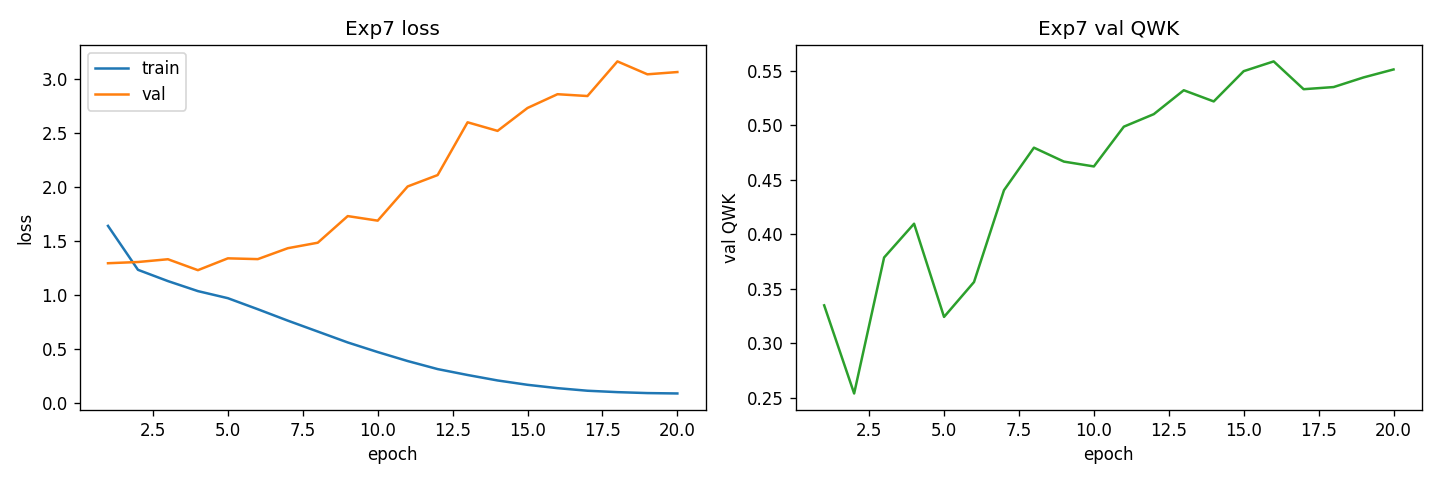

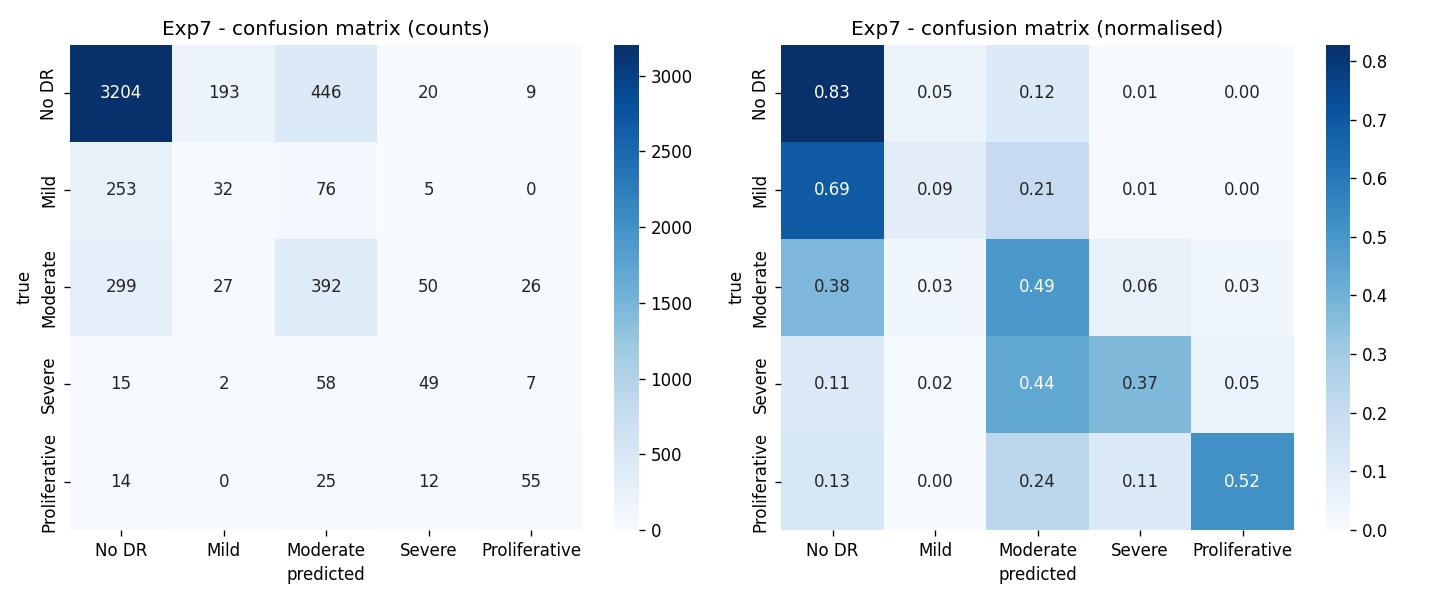

In [64]:
# ── Exp7 summary metrics — unified set + val_top2_acc history ─────────
from sklearn.metrics import precision_score, recall_score

exp7_qwk       = cohen_kappa_score(exp7_y_true, exp7_y_pred, weights='quadratic')
exp7_acc       = accuracy_score(exp7_y_true, exp7_y_pred)
exp7_precision = precision_score(exp7_y_true, exp7_y_pred, average='macro', zero_division=0)
exp7_recall    = recall_score(exp7_y_true, exp7_y_pred, average='macro', zero_division=0)
exp7_f1        = f1_score(exp7_y_true, exp7_y_pred, average='macro', zero_division=0)
exp7_top2_acc  = sum(1 for y, top2 in zip(exp7_y_true, exp7_top2_pred) if y in top2) / len(exp7_y_true)
exp7_report    = classification_report(exp7_y_true, exp7_y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)

print(f'Exp7 test QWK              : {exp7_qwk:.4f}')
print(f'Exp7 test accuracy         : {exp7_acc:.4f}')
print(f'Exp7 test precision (macro): {exp7_precision:.4f}')
print(f'Exp7 test recall    (macro): {exp7_recall:.4f}')
print(f'Exp7 test F1        (macro): {exp7_f1:.4f}')
print(f'Exp7 test top-2 accuracy   : {exp7_top2_acc:.4f}')
print(f'Exp7 best epoch            : {exp7_best_epoch}')
print()
print(exp7_report)

exp7_summary = {
    'experiment': 'exp7_class_weights_only',
    'test_qwk': exp7_qwk,
    'test_acc': exp7_acc,
    'test_precision_macro': exp7_precision,
    'test_recall_macro':    exp7_recall,
    'test_f1_macro':        exp7_f1,
    'test_top2_acc':        exp7_top2_acc,
    'best_epoch': exp7_best_epoch, 'best_val_qwk': exp7_best_qwk,
    'epochs_run': len(exp7_history['train_loss']),
    'history': {
        'train_loss':   exp7_history['train_loss'],
        'val_loss':     exp7_history['val_loss'],
        'val_qwk':      exp7_history['val_qwk'],
        'val_top2_acc': exp7_history['val_top2_acc'],
    },
    'config': {'epochs': EXP7_EPOCHS, 'patience': EXP7_PATIENCE, 'peak_lr': EXP7_PEAK_LR},
    'class_weights': class_weights_exp7.cpu().numpy().tolist(),
}
with open(EXP7_OUT_DIR / 'summary.json', 'w') as f:
    json.dump(exp7_summary, f, indent=2)
print('Saved', (EXP7_OUT_DIR / 'summary.json').relative_to(ROOT))


## 18. Experiment 8 - WeightedRandomSampler Only

Isolate the effect of the sampler from class weighting. Plain CE loss,
WeightedRandomSampler with inverse-frequency weights on the training set.

Recipe: epochs=20, patience=4, peak_lr=3e-4, plain CE + sampler.

Unified metrics reported: QWK, accuracy, precision (macro), recall (macro),
F1 (macro), top-2 accuracy. Per-epoch val_top2_acc tracked.


In [65]:
# ── Run 8 config ─────────────────────────────────────────────────────
EXP8_NAME      = 'mobilenet_dr_training_exp8'
EXP8_EPOCHS    = 20
EXP8_PATIENCE  = 4
EXP8_PEAK_LR   = 3e-4
EXP8_OUT_DIR   = ROOT / 'outputs' / EXP8_NAME
EXP8_CKPT_DIR  = EXP8_OUT_DIR / 'checkpoints'
EXP8_FIG_DIR   = EXP8_OUT_DIR / 'figures'
for d in (EXP8_OUT_DIR, EXP8_CKPT_DIR, EXP8_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('Exp8 config set.')


In [66]:
from torch.optim.lr_scheduler import CosineAnnealingLR
# ── Build WeightedRandomSampler from inverse-frequency weights ────────
from torch.utils.data import WeightedRandomSampler

set_seed(SEED)

class_counts_exp8  = train_df['level'].value_counts().sort_index().values
inv_freq           = 1.0 / class_counts_exp8
sample_weights_e8  = train_df['level'].map(lambda y: inv_freq[y]).values
sample_weights_e8  = torch.as_tensor(sample_weights_e8, dtype=torch.double)
exp8_sampler       = WeightedRandomSampler(sample_weights_e8, num_samples=len(sample_weights_e8), replacement=True)

exp8_train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=exp8_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

exp8_model = timm.create_model(
    'mobilenetv3_large_100.ra_in1k',
    pretrained=True,
    num_classes=NUM_CLASSES,
).to(device)

exp8_criterion = nn.CrossEntropyLoss()
exp8_optimizer = torch.optim.AdamW(exp8_model.parameters(), lr=EXP8_PEAK_LR, weight_decay=WEIGHT_DECAY)
exp8_scheduler = CosineAnnealingLR(exp8_optimizer, T_max=EXP8_EPOCHS)
print('Exp8 sampler + model ready. Sample count per epoch:', len(sample_weights_e8))


In [67]:
# ── Run 8 training loop (with per-epoch val_top2_acc tracking) ────────
exp8_history = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_top2_acc': []}
exp8_best_qwk = -1.0
exp8_best_epoch = 0
exp8_bad_epochs = 0

_e8_baseline_model     = globals().get('model',     None)
_e8_baseline_criterion = globals().get('criterion', None)
_e8_baseline_optimizer = globals().get('optimizer', None)
model     = exp8_model
criterion = exp8_criterion
optimizer = exp8_optimizer

# local helper — captures both argmax and top-2 predictions in one val pass
def run_val_with_top2(loader):
    model.eval()
    total_loss, total = 0.0, 0
    all_preds, all_top2, all_labels = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                loss   = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_top2.extend(logits.topk(2, dim=1).indices.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
    return total_loss / total, all_labels, all_preds, all_top2

exp8_log_path = EXP8_OUT_DIR / 'train_log.txt'
with open(exp8_log_path, 'w') as flog:
    flog.write(f'Exp8 - WeightedRandomSampler only | epochs={EXP8_EPOCHS} peak_lr={EXP8_PEAK_LR}\n')

    for epoch in range(1, EXP8_EPOCHS + 1):
        train_loss, _, _                        = run_epoch(exp8_train_loader, train_mode=True)
        val_loss, val_labels, val_preds, val_t2 = run_val_with_top2(val_loader)
        exp8_scheduler.step()
        val_qwk      = cohen_kappa_score(val_labels, val_preds, weights='quadratic')
        val_top2_acc = sum(1 for y, t2 in zip(val_labels, val_t2) if y in t2) / len(val_labels)

        exp8_history['train_loss'].append(train_loss)
        exp8_history['val_loss'].append(val_loss)
        exp8_history['val_qwk'].append(val_qwk)
        exp8_history['val_top2_acc'].append(val_top2_acc)

        line = (f'[exp8 epoch {epoch:02d}] train_loss={train_loss:.4f} '
                f'val_loss={val_loss:.4f} val_qwk={val_qwk:.4f} '
                f'val_top2_acc={val_top2_acc:.4f}')
        print(line); flog.write(line + '\n'); flog.flush()

        if val_qwk > exp8_best_qwk:
            exp8_best_qwk   = val_qwk
            exp8_best_epoch = epoch
            exp8_bad_epochs = 0
            torch.save(exp8_model.state_dict(), CKPT_EXP8)
            print(f'  -> new best val_qwk={val_qwk:.4f}, saved {CKPT_EXP8.name}')
        else:
            exp8_bad_epochs += 1
            if exp8_bad_epochs >= EXP8_PATIENCE:
                print(f'  -> early stop at epoch {epoch} (patience={EXP8_PATIENCE})')
                flog.write(f'  early stop at epoch {epoch}\n')
                break

if _e8_baseline_model     is not None: model     = _e8_baseline_model
if _e8_baseline_criterion is not None: criterion = _e8_baseline_criterion
if _e8_baseline_optimizer is not None: optimizer = _e8_baseline_optimizer

print(f'Exp8 done. Best val_qwk={exp8_best_qwk:.4f} at epoch {exp8_best_epoch}')


In [68]:
# ── Run 8 loss + qwk curve ────────────────────────────────────────────
epochs_ran_exp8 = range(1, len(exp8_history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs_ran_exp8, exp8_history['train_loss'], label='train')
ax1.plot(epochs_ran_exp8, exp8_history['val_loss'],   label='val')
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.legend(); ax1.set_title('Exp8 loss')
ax2.plot(epochs_ran_exp8, exp8_history['val_qwk'], color='tab:green')
ax2.set_xlabel('epoch'); ax2.set_ylabel('val QWK'); ax2.set_title('Exp8 val QWK')
fig.tight_layout()
fig.savefig(EXP8_FIG_DIR / 'loss_qwk_curve.png', dpi=120)
plt.show()


In [69]:
# ── Independent of training cell - requires Sections 1-7 + checkpoint registry ─
exp8_eval_model = timm.create_model('mobilenetv3_large_100.ra_in1k', pretrained=False, num_classes=NUM_CLASSES).to(device)
exp8_eval_model.load_state_dict(torch.load(CKPT_EXP8, map_location=device))
exp8_eval_model.eval()

exp8_y_true, exp8_y_pred, exp8_top2_pred = [], [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='exp8 test'):
        images = images.to(device, non_blocking=True)
        logits = exp8_eval_model(images)
        exp8_y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        top2_idx = logits.topk(2, dim=1).indices.cpu().tolist()
        exp8_top2_pred.extend(top2_idx)
        exp8_y_true.extend(labels.tolist())

cm_exp8 = confusion_matrix(exp8_y_true, exp8_y_pred)
cm_exp8_norm = cm_exp8.astype(float) / cm_exp8.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_exp8, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Exp8 - confusion matrix (counts)'); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true')
sns.heatmap(cm_exp8_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Exp8 - confusion matrix (normalised)'); axes[1].set_xlabel('predicted'); axes[1].set_ylabel('true')
fig.tight_layout()
fig.savefig(EXP8_FIG_DIR / 'confusion_matrix.png', dpi=120)
plt.show()


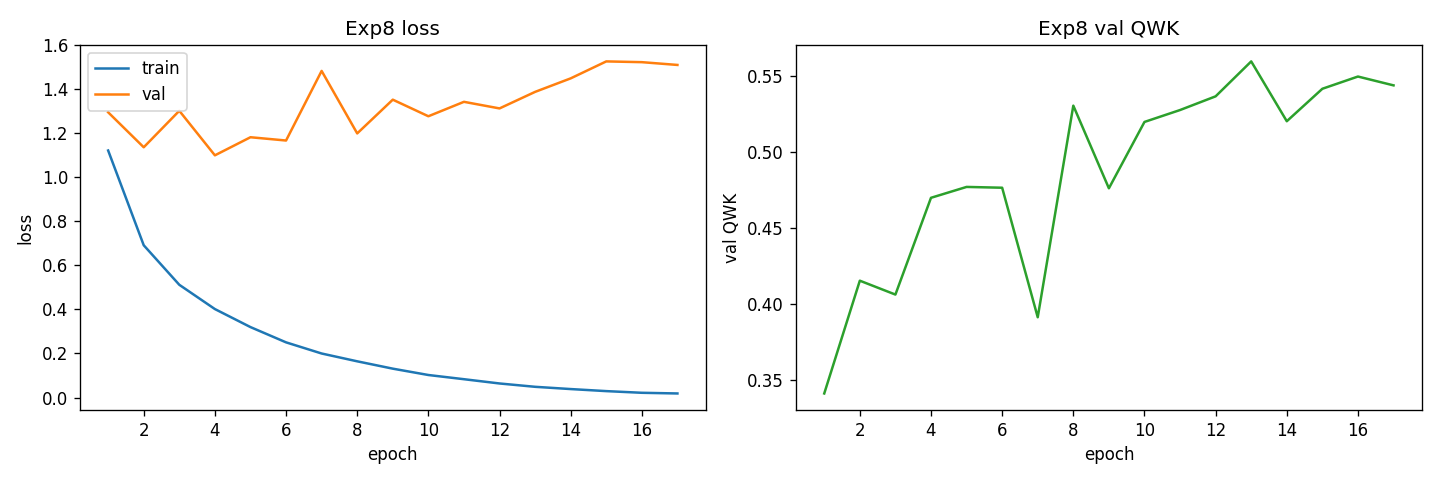

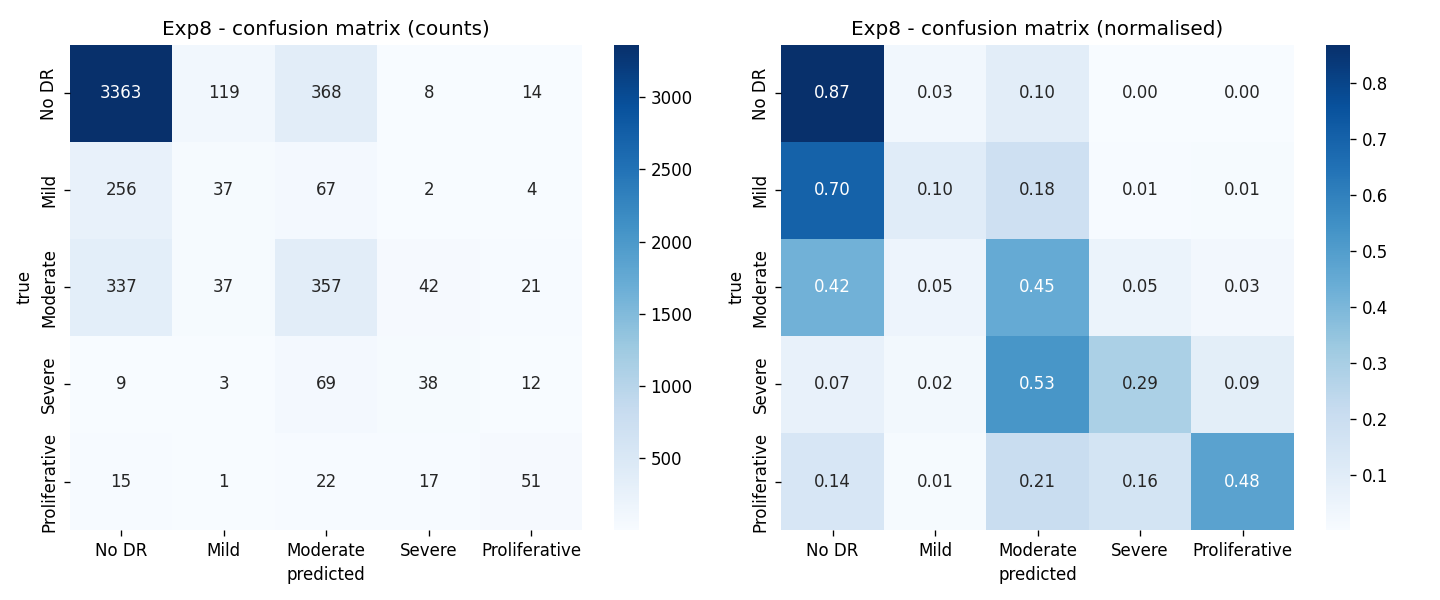

In [70]:
# ── Exp8 summary metrics — unified set + val_top2_acc history ─────────
from sklearn.metrics import precision_score, recall_score

exp8_qwk       = cohen_kappa_score(exp8_y_true, exp8_y_pred, weights='quadratic')
exp8_acc       = accuracy_score(exp8_y_true, exp8_y_pred)
exp8_precision = precision_score(exp8_y_true, exp8_y_pred, average='macro', zero_division=0)
exp8_recall    = recall_score(exp8_y_true, exp8_y_pred, average='macro', zero_division=0)
exp8_f1        = f1_score(exp8_y_true, exp8_y_pred, average='macro', zero_division=0)
exp8_top2_acc  = sum(1 for y, top2 in zip(exp8_y_true, exp8_top2_pred) if y in top2) / len(exp8_y_true)
exp8_report    = classification_report(exp8_y_true, exp8_y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)

print(f'Exp8 test QWK              : {exp8_qwk:.4f}')
print(f'Exp8 test accuracy         : {exp8_acc:.4f}')
print(f'Exp8 test precision (macro): {exp8_precision:.4f}')
print(f'Exp8 test recall    (macro): {exp8_recall:.4f}')
print(f'Exp8 test F1        (macro): {exp8_f1:.4f}')
print(f'Exp8 test top-2 accuracy   : {exp8_top2_acc:.4f}')
print(f'Exp8 best epoch            : {exp8_best_epoch}')
print()
print(exp8_report)

exp8_summary = {
    'experiment': 'exp8_weighted_random_sampler_only',
    'test_qwk': exp8_qwk,
    'test_acc': exp8_acc,
    'test_precision_macro': exp8_precision,
    'test_recall_macro':    exp8_recall,
    'test_f1_macro':        exp8_f1,
    'test_top2_acc':        exp8_top2_acc,
    'best_epoch': exp8_best_epoch, 'best_val_qwk': exp8_best_qwk,
    'epochs_run': len(exp8_history['train_loss']),
    'history': {
        'train_loss':   exp8_history['train_loss'],
        'val_loss':     exp8_history['val_loss'],
        'val_qwk':      exp8_history['val_qwk'],
        'val_top2_acc': exp8_history['val_top2_acc'],
    },
    'config': {'epochs': EXP8_EPOCHS, 'patience': EXP8_PATIENCE, 'peak_lr': EXP8_PEAK_LR,
               'sampler': 'WeightedRandomSampler(inv_freq)'},
}
with open(EXP8_OUT_DIR / 'summary.json', 'w') as f:
    json.dump(exp8_summary, f, indent=2)
print('Saved', (EXP8_OUT_DIR / 'summary.json').relative_to(ROOT))


## 19. Experiment 9 - Exp5 Pushed Harder + TTA

Take the best recipe (Exp 5 - capped Grade 0 + weighted CE + focal + sampler),
push it further with longer training and warmup, then add Test-Time
Augmentation at evaluation to squeeze out a final boost.

Recipe: epochs=25, patience=5, 2-epoch warmup, peak_lr=5e-4, cap Grade 0 at 8000,
weighted CE + focal (gamma=2), WeightedRandomSampler, TTA=4 at test.

Unified metrics reported (TTA-based): QWK, accuracy, precision (macro),
recall (macro), F1 (macro), top-2 accuracy. Per-epoch val_top2_acc tracked.


In [71]:
# ── Run 9 config ─────────────────────────────────────────────────────
EXP9_NAME      = 'mobilenet_dr_training_exp9'
EXP9_EPOCHS    = 25
EXP9_PATIENCE  = 5
EXP9_WARMUP    = 2
EXP9_PEAK_LR   = 5e-4
EXP9_GRADE0_CAP = 8000
EXP9_FOCAL_GAMMA = 2.0
EXP9_OUT_DIR   = ROOT / 'outputs' / EXP9_NAME
EXP9_CKPT_DIR  = EXP9_OUT_DIR / 'checkpoints'
EXP9_FIG_DIR   = EXP9_OUT_DIR / 'figures'
for d in (EXP9_OUT_DIR, EXP9_CKPT_DIR, EXP9_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('Exp9 config set.')


Exp9 config set.


In [72]:
# ── Cap Grade 0 + build sampler + class weights + focal loss ──────────
from torch.utils.data import WeightedRandomSampler

set_seed(SEED)

g0_df    = train_df[train_df['level'] == 0].sample(n=EXP9_GRADE0_CAP, random_state=SEED)
other_df = train_df[train_df['level'] != 0]
train_df_exp9 = pd.concat([g0_df, other_df]).sample(frac=1, random_state=SEED).reset_index(drop=True)
print('Exp9 capped train distribution:')
print(train_df_exp9['level'].value_counts().sort_index())

train_dataset_exp9 = DRDataset(train_df_exp9, TRAIN_DIR, train_transform)

class_counts_exp9  = train_df_exp9['level'].value_counts().sort_index().values
inv_freq_exp9      = 1.0 / class_counts_exp9
sample_weights_e9  = train_df_exp9['level'].map(lambda y: inv_freq_exp9[y]).values
sample_weights_e9  = torch.as_tensor(sample_weights_e9, dtype=torch.double)
exp9_sampler       = WeightedRandomSampler(sample_weights_e9, num_samples=len(sample_weights_e9), replacement=True)

exp9_train_loader = DataLoader(
    train_dataset_exp9,
    batch_size=BATCH_SIZE,
    sampler=exp9_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

class_weights_exp9 = torch.tensor(
    class_counts_exp9.sum() / (NUM_CLASSES * class_counts_exp9),
    dtype=torch.float32,
).to(device)
print('Exp9 class weights:', class_weights_exp9.cpu().numpy().round(3))

class WeightedCEFocalLoss(nn.Module):
    def __init__(self, class_weights, gamma):
        super().__init__()
        self.ce_w  = nn.CrossEntropyLoss()
        self.focal = FocalLoss(alpha=class_weights, gamma=gamma)
    def forward(self, logits, targets):
        return 0.5 * self.ce_w(logits, targets) + 0.5 * self.focal(logits, targets)

exp9_criterion = WeightedCEFocalLoss(class_weights_exp9, EXP9_FOCAL_GAMMA)
print('Exp9 sampler + loss ready.')


Exp9 capped train distribution:
level
0    8000
1    1710
2    3704
3     611
4     496
Name: count, dtype: int64
Exp9 class weights: [0.363 1.698 0.784 4.753 5.855]
Exp9 sampler + loss ready.


In [73]:
# ── Build model + warmup-cosine schedule for Run 9 ────────────────────
from torch.optim.lr_scheduler import CosineAnnealingLR, SequentialLR, LinearLR

exp9_model = timm.create_model(
    'mobilenetv3_large_100.ra_in1k',
    pretrained=True,
    num_classes=NUM_CLASSES,
).to(device)

exp9_optimizer = torch.optim.AdamW(exp9_model.parameters(), lr=EXP9_PEAK_LR, weight_decay=WEIGHT_DECAY)
exp9_warmup    = LinearLR(exp9_optimizer, start_factor=0.01, end_factor=1.0, total_iters=EXP9_WARMUP)
exp9_cosine    = CosineAnnealingLR(exp9_optimizer, T_max=max(1, EXP9_EPOCHS - EXP9_WARMUP))
exp9_scheduler = SequentialLR(exp9_optimizer, schedulers=[exp9_warmup, exp9_cosine], milestones=[EXP9_WARMUP])
print('Exp9 model + scheduler ready.')


Exp9 model + scheduler ready.


In [74]:
# ── Run 9 training loop (with per-epoch val_top2_acc tracking) ────────
exp9_history = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_top2_acc': []}
exp9_best_qwk = -1.0
exp9_best_epoch = 0
exp9_bad_epochs = 0

_e9_baseline_model     = globals().get('model',     None)
_e9_baseline_criterion = globals().get('criterion', None)
_e9_baseline_optimizer = globals().get('optimizer', None)
model     = exp9_model
criterion = exp9_criterion
optimizer = exp9_optimizer

# local helper — captures both argmax and top-2 predictions in one val pass
def run_val_with_top2(loader):
    model.eval()
    total_loss, total = 0.0, 0
    all_preds, all_top2, all_labels = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                loss   = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_top2.extend(logits.topk(2, dim=1).indices.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
    return total_loss / total, all_labels, all_preds, all_top2

exp9_log_path = EXP9_OUT_DIR / 'train_log.txt'
with open(exp9_log_path, 'w') as flog:
    flog.write(f'Exp9 - exp5 pushed harder + TTA | epochs={EXP9_EPOCHS} peak_lr={EXP9_PEAK_LR} cap_grade0={EXP9_GRADE0_CAP}\n')

    for epoch in range(1, EXP9_EPOCHS + 1):
        train_loss, _, _                        = run_epoch(exp9_train_loader, train_mode=True)
        val_loss, val_labels, val_preds, val_t2 = run_val_with_top2(val_loader)
        exp9_scheduler.step()
        val_qwk      = cohen_kappa_score(val_labels, val_preds, weights='quadratic')
        val_top2_acc = sum(1 for y, t2 in zip(val_labels, val_t2) if y in t2) / len(val_labels)

        exp9_history['train_loss'].append(train_loss)
        exp9_history['val_loss'].append(val_loss)
        exp9_history['val_qwk'].append(val_qwk)
        exp9_history['val_top2_acc'].append(val_top2_acc)

        line = (f'[exp9 epoch {epoch:02d}] train_loss={train_loss:.4f} '
                f'val_loss={val_loss:.4f} val_qwk={val_qwk:.4f} '
                f'val_top2_acc={val_top2_acc:.4f}')
        print(line); flog.write(line + '\n'); flog.flush()

        if val_qwk > exp9_best_qwk:
            exp9_best_qwk   = val_qwk
            exp9_best_epoch = epoch
            exp9_bad_epochs = 0
            torch.save(exp9_model.state_dict(), CKPT_EXP9)
            print(f'  -> new best val_qwk={val_qwk:.4f}, saved {CKPT_EXP9.name}')
        else:
            exp9_bad_epochs += 1
            if exp9_bad_epochs >= EXP9_PATIENCE:
                print(f'  -> early stop at epoch {epoch} (patience={EXP9_PATIENCE})')
                flog.write(f'  early stop at epoch {epoch}\n')
                break

if _e9_baseline_model     is not None: model     = _e9_baseline_model
if _e9_baseline_criterion is not None: criterion = _e9_baseline_criterion
if _e9_baseline_optimizer is not None: optimizer = _e9_baseline_optimizer

print(f'Exp9 done. Best val_qwk={exp9_best_qwk:.4f} at epoch {exp9_best_epoch}')


train:   0%|          | 0/454 [00:00<?, ?it/s]

[exp9 epoch 01] train_loss=3.3091 val_loss=2.1155 val_qwk=0.0725 val_top2_acc=0.3767
  -> new best val_qwk=0.0725, saved mobilenet_dr_training_exp9_best.pt


train:   0%|          | 0/454 [00:00<?, ?it/s]

[exp9 epoch 02] train_loss=1.5293 val_loss=1.0998 val_qwk=0.2882 val_top2_acc=0.6935
  -> new best val_qwk=0.2882, saved mobilenet_dr_training_exp9_best.pt


train:   0%|          | 0/454 [00:00<?, ?it/s]

...

[exp9 epoch 21] train_loss=0.0264 val_loss=1.4937 val_qwk=0.4510 val_top2_acc=0.8812


train:   0%|          | 0/454 [00:00<?, ?it/s]

[exp9 epoch 22] train_loss=0.0220 val_loss=1.5621 val_qwk=0.4459 val_top2_acc=0.8827


train:   0%|          | 0/454 [00:00<?, ?it/s]

[exp9 epoch 23] train_loss=0.0197 val_loss=1.5468 val_qwk=0.4566 val_top2_acc=0.8871
  -> early stop at epoch 23 (patience=5)
Exp9 done. Best val_qwk=0.5020 at epoch 18


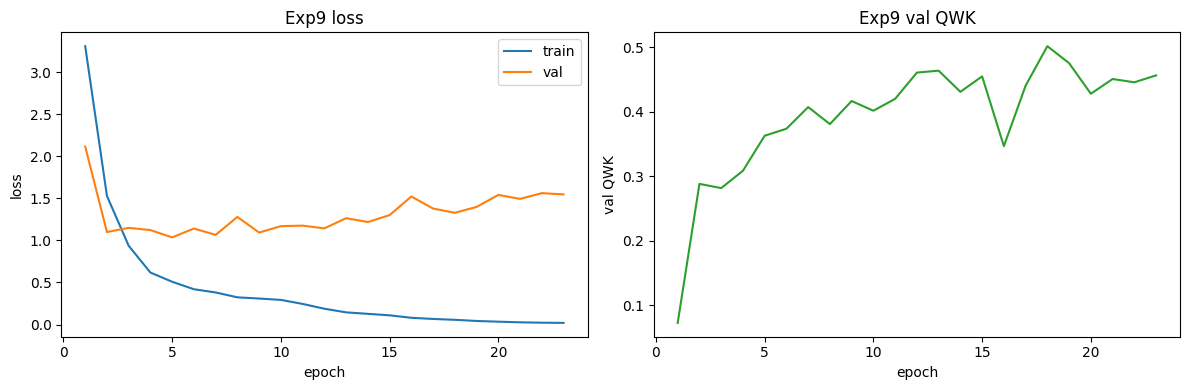

In [75]:
# ── Run 9 loss + qwk curve ────────────────────────────────────────────
epochs_ran_exp9 = range(1, len(exp9_history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs_ran_exp9, exp9_history['train_loss'], label='train')
ax1.plot(epochs_ran_exp9, exp9_history['val_loss'],   label='val')
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.legend(); ax1.set_title('Exp9 loss')
ax2.plot(epochs_ran_exp9, exp9_history['val_qwk'], color='tab:green')
ax2.set_xlabel('epoch'); ax2.set_ylabel('val QWK'); ax2.set_title('Exp9 val QWK')
fig.tight_layout()
fig.savefig(EXP9_FIG_DIR / 'loss_qwk_curve.png', dpi=120)
plt.show()


/tmp/ipykernel_259890/1037312446.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  exp9_eval_model.load_state_dict(torch.load(CKPT_EXP9, map_location=device))


exp9 TTA test:   0%|          | 0/165 [00:00<?, ?it/s]

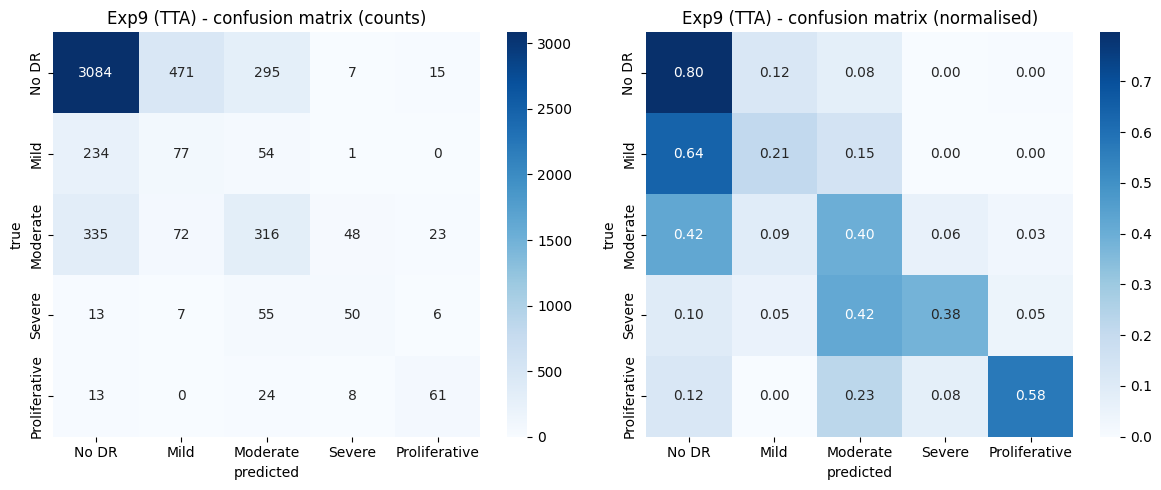

In [76]:
# ── Run 9 TTA evaluation (4 views: identity + hflip + vflip + both) ─────
exp9_eval_model = timm.create_model('mobilenetv3_large_100.ra_in1k', pretrained=False, num_classes=NUM_CLASSES).to(device)
exp9_eval_model.load_state_dict(torch.load(CKPT_EXP9, map_location=device))
exp9_eval_model.eval()

exp9_y_true, exp9_y_pred, exp9_top2_pred = [], [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='exp9 TTA test'):
        images = images.to(device, non_blocking=True)
        v1 = exp9_eval_model(images).softmax(dim=1)
        v2 = exp9_eval_model(torch.flip(images, dims=[3])).softmax(dim=1)
        v3 = exp9_eval_model(torch.flip(images, dims=[2])).softmax(dim=1)
        v4 = exp9_eval_model(torch.flip(images, dims=[2, 3])).softmax(dim=1)
        probs = (v1 + v2 + v3 + v4) / 4.0
        exp9_y_pred.extend(probs.argmax(dim=1).cpu().tolist())
        top2_idx = probs.topk(2, dim=1).indices.cpu().tolist()
        exp9_top2_pred.extend(top2_idx)
        exp9_y_true.extend(labels.tolist())

cm_exp9 = confusion_matrix(exp9_y_true, exp9_y_pred)
cm_exp9_norm = cm_exp9.astype(float) / cm_exp9.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_exp9, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Exp9 (TTA) - confusion matrix (counts)'); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true')
sns.heatmap(cm_exp9_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Exp9 (TTA) - confusion matrix (normalised)'); axes[1].set_xlabel('predicted'); axes[1].set_ylabel('true')
fig.tight_layout()
fig.savefig(EXP9_FIG_DIR / 'confusion_matrix.png', dpi=120)
plt.show()


In [77]:
# ── Exp9 summary metrics (TTA) — unified set + val_top2_acc history ────
from sklearn.metrics import precision_score, recall_score

exp9_qwk       = cohen_kappa_score(exp9_y_true, exp9_y_pred, weights='quadratic')
exp9_acc       = accuracy_score(exp9_y_true, exp9_y_pred)
exp9_precision = precision_score(exp9_y_true, exp9_y_pred, average='macro', zero_division=0)
exp9_recall    = recall_score(exp9_y_true, exp9_y_pred, average='macro', zero_division=0)
exp9_f1        = f1_score(exp9_y_true, exp9_y_pred, average='macro', zero_division=0)
exp9_top2_acc  = sum(1 for y, top2 in zip(exp9_y_true, exp9_top2_pred) if y in top2) / len(exp9_y_true)
exp9_report    = classification_report(exp9_y_true, exp9_y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)

print(f'Exp9 (TTA) test QWK              : {exp9_qwk:.4f}')
print(f'Exp9 (TTA) test accuracy         : {exp9_acc:.4f}')
print(f'Exp9 (TTA) test precision (macro): {exp9_precision:.4f}')
print(f'Exp9 (TTA) test recall    (macro): {exp9_recall:.4f}')
print(f'Exp9 (TTA) test F1        (macro): {exp9_f1:.4f}')
print(f'Exp9 (TTA) test top-2 accuracy   : {exp9_top2_acc:.4f}')
print(f'Exp9 best epoch                  : {exp9_best_epoch}')
print()
print(exp9_report)

exp9_summary = {
    'experiment': 'exp9_exp5_pushed_harder_plus_tta',
    'test_qwk': exp9_qwk,
    'test_acc': exp9_acc,
    'test_precision_macro': exp9_precision,
    'test_recall_macro':    exp9_recall,
    'test_f1_macro':        exp9_f1,
    'test_top2_acc':        exp9_top2_acc,
    'best_epoch': exp9_best_epoch, 'best_val_qwk': exp9_best_qwk,
    'epochs_run': len(exp9_history['train_loss']),
    'history': {
        'train_loss':   exp9_history['train_loss'],
        'val_loss':     exp9_history['val_loss'],
        'val_qwk':      exp9_history['val_qwk'],
        'val_top2_acc': exp9_history['val_top2_acc'],
    },
    'config': {'epochs': EXP9_EPOCHS, 'patience': EXP9_PATIENCE,
               'warmup_epochs': EXP9_WARMUP, 'peak_lr': EXP9_PEAK_LR,
               'grade0_cap': EXP9_GRADE0_CAP, 'focal_gamma': EXP9_FOCAL_GAMMA,
               'tta_views': 4},
    'class_weights': class_weights_exp9.cpu().numpy().tolist(),
}
with open(EXP9_OUT_DIR / 'summary.json', 'w') as f:
    json.dump(exp9_summary, f, indent=2)
print('Saved', (EXP9_OUT_DIR / 'summary.json').relative_to(ROOT))


Exp9 (TTA) test QWK              : 0.5550
Exp9 (TTA) test accuracy         : 0.6810
Exp9 (TTA) test precision (macro): 0.4811
Exp9 (TTA) test recall    (macro): 0.4724
Exp9 (TTA) test F1        (macro): 0.4738
Exp9 (TTA) test top-2 accuracy   : 0.8933
Exp9 best epoch                  : 18

               precision    recall  f1-score   support

        No DR     0.8383    0.7965    0.8168      3872
         Mild     0.1228    0.2104    0.1551       366
     Moderate     0.4247    0.3980    0.4109       794
       Severe     0.4386    0.3817    0.4082       131
Proliferative     0.5810    0.5755    0.5782       106

     accuracy                         0.6810      5269
    macro avg     0.4811    0.4724    0.4738      5269
 weighted avg     0.7111    0.6810    0.6947      5269

Saved outputs/mobilenet_dr_training_exp9/summary.json


## 20. Final Ablation Summary

Later experiments (Run 6-9) re-tested key approaches with a stronger training recipe. Run 6 uses plain cross-entropy on the strong recipe and gives the highest QWK; Run 9 keeps the same recipe but adds imbalance-aware techniques (Focal loss, class cap, TTA) which hurt the score. This section pulls the saved metrics for all four ablation runs into one view.

In [1]:
# pulling each ablation summary.json into one row
import json
import pandas as pd
from pathlib import Path

ABL_RUNS = ['exp6', 'exp7', 'exp8', 'exp9']
ABL_LABELS = {
    'exp6': 'Run 6 - Plain CE pushed (best)',
    'exp7': 'Run 7 - Class weights only',
    'exp8': 'Run 8 - WeightedRandomSampler only',
    'exp9': 'Run 9 - Focal + TTA + cap',
}

rows = []
for k in ABL_RUNS:
    # checking both possible relative paths (notebook root vs project root)
    for p in [Path(f'../outputs/mobilenet_dr_training_{k}/summary.json'),
              Path(f'outputs/mobilenet_dr_training_{k}/summary.json')]:
        if p.exists():
            d = json.load(open(p))
            rows.append({
                'Run': ABL_LABELS[k],
                'QWK': round(d.get('test_qwk', 0), 4),
                'Accuracy': round(d.get('test_acc', 0), 4),
                'Top-2 Acc': round(d.get('test_top2_acc', 0), 4),
                'Macro F1': round(d.get('test_f1_macro', 0), 4),
                'Best Epoch': d.get('best_epoch', '-'),
            })
            break

df_ablation = pd.DataFrame(rows)
df_ablation


,Run,QWK,Accuracy,Top-2 Acc,Macro F1,Best Epoch
0,Run 6 - Plain CE pushed (best),0.6339,0.7781,0.9102,0.4676,17
1,Run 7 - Class weights only,0.5533,0.7083,0.9083,0.4574,16
2,Run 8 - WeightedRandomSampler only,0.5668,0.7299,0.9023,0.4447,13
3,Run 9 - Focal + TTA + cap,0.5550,0.6810,0.8933,0.4738,18


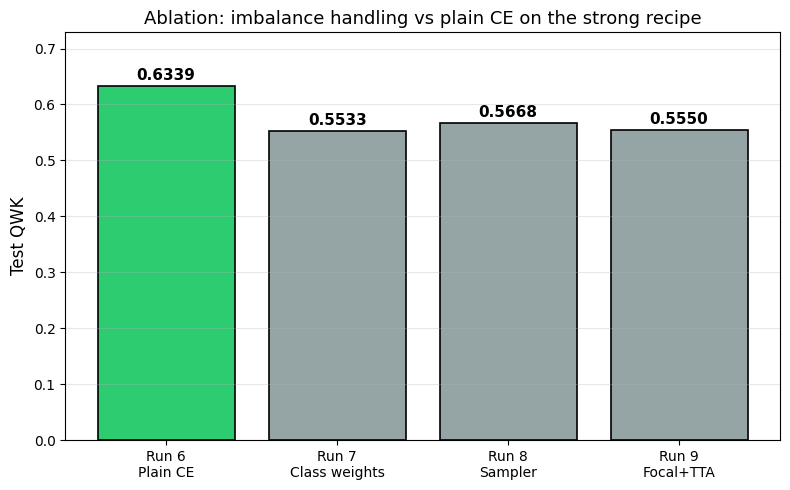

saved: ../outputs/figures/ablation_qwk_bar.png


In [2]:
# headline bar chart - QWK across the four ablation runs
import matplotlib.pyplot as plt
import os

labels = ['Run 6\nPlain CE', 'Run 7\nClass weights', 'Run 8\nSampler', 'Run 9\nFocal+TTA']
qwks = df_ablation['QWK'].values
# winning run in green, others grey - quick visual scan
colors = ['#2ecc71' if q == qwks.max() else '#95a5a6' for q in qwks]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, qwks, color=colors, edgecolor='black', linewidth=1.2)

# annotating each bar with its numeric value
for bar, q in zip(bars, qwks):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{q:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Test QWK', fontsize=12)
ax.set_title('Ablation: imbalance handling vs plain CE on the strong recipe', fontsize=13)
ax.set_ylim(0, max(qwks) * 1.15)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

# saving a standalone png so it can be dropped into the IEEE report
out_dir = '../outputs/figures' if os.path.isdir('../outputs/figures') else 'outputs/figures'
out_path = os.path.join(out_dir, 'ablation_qwk_bar.png')
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'saved: {out_path}')


In [3]:
# final recommendation block
best_idx = df_ablation['QWK'].idxmax()
best_row = df_ablation.iloc[best_idx]

print('=' * 60)
print('FINAL RECOMMENDATION')
print('=' * 60)
print(f"Chosen run : {best_row['Run']}")
print(f"Test QWK   : {best_row['QWK']}")
print(f"Test Acc   : {best_row['Accuracy']}")
print(f"Top-2 Acc  : {best_row['Top-2 Acc']}")
print(f"Macro F1   : {best_row['Macro F1']}")
print(f"Best epoch : {best_row['Best Epoch']}")
print('=' * 60)
print()
print('Why this run wins:')
print(' - Plain CE on a longer schedule with warmup outperformed every imbalance-aware variant.')
print(' - Run 9 used the same recipe plus Focal + TTA + class cap and scored lower.')
print(' - Suggests recipe (epochs, LR, warmup) mattered more than the loss tricks.')


FINAL RECOMMENDATION
Chosen run : Run 6 - Plain CE pushed (best)
Test QWK   : 0.6339
Test Acc   : 0.7781
Top-2 Acc  : 0.9102
Macro F1   : 0.4676
Best epoch : 17

Why this run wins:
 - Plain CE on a longer schedule with warmup outperformed every imbalance-aware variant.
 - Run 9 used the same recipe plus Focal + TTA + class cap and scored lower.
 - Suggests recipe (epochs, LR, warmup) mattered more than the loss tricks.
